# DEAP: baseline context, multicollinearity and subject personalization
Updated implementation of the professor's four requests. All outputs are intentionally cleared: **no new DEAP results are claimed**.

1. Diagnose pairwise correlation, VIF, matrix rank and condition number before/after filtering.
2. Use the available **3-second pre-stimulus baseline** as trial-specific resting context.
3. Calibrate with the stimulus time 5–32.5 s (starting at the 6th second) and test on 32.5–60 s, splitting before additional filtering.
4. Compute **384 × 384 feature correlations** on source training subjects, retaining features at a high threshold (0.90).

Also retain a separate **unseen-trial** experiment (20 calibration / 20 test trials) and compare general versus personalized explanations. Temporal halves share a trial label; their results must not be presented as unseen-trial generalization. Official preprocessed recordings may already contain processing across time boundaries; splitting here cannot undo that processing.

Read each section in order. Start by editing DATA_DIR. The label audit now uses supplied participant metadata, with video-order alignment checks before fitting. This notebook replaces the earlier general-only implementation; earlier results are not comparable without rerunning under the same design.

**Revision:** correlation threshold 0.90; calibration begins at the 6th stimulus second. Both halves are 27.5 s. Restart the kernel and run all cells; old extracted features must not be reused. Invalid-label reports distinguish Valence from unused targets.

**Metadata repair:** use the embedded supplied reference for every Valence label; do not reuse previous feature tables containing old targets or prior metrics. Range-valid entries may also have been transformed.

In [1]:
# Uncomment once if required, then restart the kernel.
# %pip install numpy pandas scipy scikit-learn matplotlib joblib

In [2]:
from pathlib import Path
import json, pickle, hashlib, warnings, platform
import numpy as np
import pandas as pd
import scipy, sklearn
from scipy.signal import welch, butter, sosfiltfilt
from scipy.stats import wilcoxon
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.exceptions import ConvergenceWarning
import matplotlib.pyplot as plt
import joblib

DATA_DIR = Path(r'D:\coding\python\HCI RESEARCH PROJECT\imlementation\data_preprocessed_python')
OUT = Path('deap_professor_updated_results')
OUT.mkdir(exist_ok=True, parents=True)
FS = 128
BASELINE_SAMPLES = 3 * FS
# "6th second" means stimulus time t=5 s, after the separate 3-s baseline.
CALIBRATION_START_SECOND = 6
STIMULUS_SKIP_SAMPLES = (CALIBRATION_START_SECOND - 1) * FS
REMAINING_SAMPLES = 60 * FS - STIMULUS_SKIP_SAMPLES
assert REMAINING_SAMPLES > 0 and REMAINING_SAMPLES % 2 == 0
HALF_SAMPLES = REMAINING_SAMPLES // 2  # 3520 = 27.5 s per half
STIMULUS_START_SAMPLE = BASELINE_SAMPLES + STIMULUS_SKIP_SAMPLES
TEMPORAL_SPLIT_SAMPLE = STIMULUS_START_SAMPLE + HALF_SAMPLES
BANDS = {'theta': (4,8), 'alpha': (8,13), 'beta': (13,30), 'gamma': (30,45)}
CORRELATION_THRESHOLD = 0.90
CALIBRATION_WEIGHT = 10.0
C = 1.0  # fixed a priori; tune only with nested source-subject validation
SEEDS = [42]  # optionally [42, 123, 2026]; aggregate repeats within subject for inference
FEATURE_MODES = ['stimulus', 'baseline_relative']
PROTOCOLS = ['temporal_halves', 'unseen_trials']
XAI_TOP_K = 10
XAI_RANDOM_REPEATS = 30
XAI_NOISE_REPEATS = 10
XAI_NOISE_SD = 0.05  # standardized feature units
RUN_XAI = True
# Optional CSV: subject_id,trial_id,valence_rating,verification_source.
# Only enter corrections independently verified against official participant metadata.
CORRECTIONS_CSV = None
ALLOW_PARTIAL_DATA = False
print('Versions:', platform.python_version(), np.__version__, scipy.__version__, sklearn.__version__)

Versions: 3.11.13 2.4.0 1.15.2 1.8.0


## 1. Metadata-backed label repair and alignment verification
All 163 reported out-of-range entries match `9 − reference rating` when aligned by `Participant_id` and `Experiment_id`. This supports a systematic transformation, not 163 unrelated missing ratings. **In-range values can also be transformed**, so use reference labels for all 1,280 trials rather than patching only flagged entries.

The necessary values from the uploaded participant_ratings.xls are embedded below. No separate metadata path or Excel engine is needed to run this notebook. The spreadsheet's SHA256 is recorded. Standard preprocessed data is in video (`Experiment_id`) order; the spreadsheet's `Trial` is presentation order. Thus subject 1/video 21 has Valence 9.00; the earlier 2.99 claim refers to presentation trial 21 (video 11).

Before accepting that mapping locally, require every stored Dominance and Liking value to match reference values. A mismatch stops fitting for investigation; labels cannot independently prove EEG signal ordering. Save full stored-versus-reference comparisons, including whether each value matches `9 − reference`. Original .dat files are never modified. The correction dictionary used downstream covers **all** Valence labels.

All earlier class counts and predictive/explanation results need recomputation. The supplied metadata gives **708 high (>5) and 572 low (≤5) Valence trials**. Do not interpret the previous 79%/21% imbalance as the corrected dataset's distribution.

In [3]:
# Reference supplied in participant_ratings.xls; embedded for portable execution.
# Columns: subject, video/Experiment_id, presentation Trial, Valence, Arousal, Dominance, Liking.
# Preprocessed DEAP uses video order, not presentation order.
REFERENCE_ROWS = [[1.0, 1.0, 24.0, 7.71, 7.6, 6.9, 7.83], [1.0, 2.0, 36.0, 8.1, 7.31, 7.28, 8.47], [1.0, 3.0, 32.0, 8.58, 7.54, 9.0, 7.08], [1.0, 4.0, 3.0, 4.94, 6.01, 6.12, 8.06], [1.0, 5.0, 1.0, 6.96, 3.92, 7.19, 6.05], [1.0, 6.0, 11.0, 8.27, 3.92, 7.0, 8.03], [1.0, 7.0, 25.0, 7.44, 3.73, 7.08, 7.04], [1.0, 8.0, 31.0, 7.32, 2.55, 6.32, 5.87], [1.0, 9.0, 39.0, 4.04, 3.29, 3.62, 5.99], [1.0, 10.0, 12.0, 1.99, 4.86, 2.04, 7.09], [1.0, 11.0, 21.0, 2.99, 2.36, 3.63, 6.24], [1.0, 12.0, 27.0, 2.71, 2.77, 3.4, 7.35], [1.0, 13.0, 9.0, 1.95, 3.12, 2.87, 6.18], [1.0, 14.0, 19.0, 4.18, 2.24, 3.04, 5.04], [1.0, 15.0, 15.0, 3.17, 8.08, 2.91, 5.04], [1.0, 16.0, 28.0, 6.81, 7.44, 8.15, 7.14], [1.0, 17.0, 16.0, 2.46, 6.91, 6.77, 6.41], [1.0, 18.0, 2.0, 7.23, 7.15, 6.94, 8.01], [1.0, 19.0, 35.0, 7.17, 8.0, 8.1, 6.79], [1.0, 20.0, 5.0, 8.26, 7.91, 7.19, 8.13], [1.0, 21.0, 37.0, 9.0, 7.95, 8.37, 7.86], [1.0, 22.0, 14.0, 7.09, 2.08, 7.06, 7.37], [1.0, 23.0, 38.0, 8.15, 3.01, 7.37, 7.9], [1.0, 24.0, 4.0, 7.04, 7.09, 8.01, 8.22], [1.0, 25.0, 29.0, 8.86, 7.21, 8.65, 7.21], [1.0, 26.0, 40.0, 7.28, 7.27, 7.41, 8.24], [1.0, 27.0, 20.0, 7.35, 6.95, 7.03, 7.29], [1.0, 28.0, 30.0, 3.88, 3.35, 4.01, 7.87], [1.0, 29.0, 23.0, 1.36, 2.27, 3.0, 8.14], [1.0, 30.0, 22.0, 2.08, 2.99, 3.22, 7.33], [1.0, 31.0, 6.0, 3.03, 8.14, 2.86, 8.04], [1.0, 32.0, 26.0, 2.28, 8.0, 3.27, 3.95], [1.0, 33.0, 10.0, 3.81, 3.85, 4.78, 5.13], [1.0, 34.0, 18.0, 2.28, 7.09, 7.28, 6.92], [1.0, 35.0, 13.0, 2.06, 8.15, 8.05, 5.18], [1.0, 36.0, 17.0, 2.9, 6.92, 6.5, 3.87], [1.0, 37.0, 34.0, 2.31, 6.88, 3.1, 6.77], [1.0, 38.0, 33.0, 3.33, 7.18, 6.54, 6.62], [1.0, 39.0, 8.0, 3.24, 6.18, 7.87, 6.15], [1.0, 40.0, 7.0, 5.1, 7.12, 6.17, 5.97], [2.0, 1.0, 34.0, 9.0, 5.03, 7.13, 6.62], [2.0, 2.0, 20.0, 8.01, 7.1, 8.04, 8.08], [2.0, 3.0, 37.0, 9.0, 9.0, 8.96, 8.05], [2.0, 4.0, 22.0, 6.05, 1.0, 5.04, 7.03], [2.0, 5.0, 33.0, 5.04, 3.0, 3.65, 5.04], [2.0, 6.0, 16.0, 5.0, 4.94, 5.04, 1.01], [2.0, 7.0, 15.0, 4.96, 1.99, 4.08, 1.0], [2.0, 8.0, 19.0, 9.0, 9.0, 9.0, 9.0], [2.0, 9.0, 30.0, 9.0, 7.0, 9.0, 7.18], [2.0, 10.0, 39.0, 4.99, 1.0, 9.0, 1.0], [2.0, 11.0, 21.0, 7.08, 1.0, 7.01, 7.0], [2.0, 12.0, 12.0, 8.01, 6.06, 7.12, 9.0], [2.0, 13.0, 26.0, 9.0, 4.99, 9.0, 9.0], [2.0, 14.0, 24.0, 8.94, 9.0, 8.97, 9.0], [2.0, 15.0, 35.0, 9.0, 8.01, 8.06, 9.0], [2.0, 16.0, 40.0, 6.0, 5.05, 8.05, 6.14], [2.0, 17.0, 2.0, 9.0, 3.0, 6.03, 7.41], [2.0, 18.0, 18.0, 9.0, 6.15, 9.0, 8.08], [2.0, 19.0, 23.0, 9.0, 8.32, 8.06, 6.99], [2.0, 20.0, 11.0, 8.97, 9.0, 8.03, 9.0], [2.0, 21.0, 31.0, 1.0, 1.0, 5.04, 1.0], [2.0, 22.0, 32.0, 5.0, 1.0, 4.97, 5.0], [2.0, 23.0, 25.0, 1.0, 2.97, 1.0, 7.82], [2.0, 24.0, 9.0, 7.08, 9.0, 6.06, 9.0], [2.0, 25.0, 27.0, 9.0, 9.0, 8.1, 9.0], [2.0, 26.0, 17.0, 9.0, 8.04, 9.0, 9.0], [2.0, 27.0, 1.0, 4.96, 5.01, 3.01, 5.05], [2.0, 28.0, 13.0, 4.06, 4.97, 7.14, 7.04], [2.0, 29.0, 10.0, 2.99, 7.04, 7.03, 9.0], [2.0, 30.0, 7.0, 2.01, 7.05, 1.0, 7.13], [2.0, 31.0, 4.0, 4.06, 7.05, 1.0, 9.0], [2.0, 32.0, 6.0, 1.0, 9.0, 2.01, 1.0], [2.0, 33.0, 8.0, 5.0, 8.03, 3.01, 1.0], [2.0, 34.0, 38.0, 4.87, 1.0, 6.99, 1.0], [2.0, 35.0, 3.0, 1.99, 2.0, 1.0, 1.0], [2.0, 36.0, 36.0, 5.04, 1.0, 7.09, 1.0], [2.0, 37.0, 14.0, 1.0, 8.06, 1.0, 1.0], [2.0, 38.0, 5.0, 1.0, 9.0, 1.0, 1.0], [2.0, 39.0, 28.0, 1.0, 1.0, 2.97, 1.0], [2.0, 40.0, 29.0, 6.05, 6.67, 6.94, 6.53], [3.0, 1.0, 7.0, 5.33, 4.67, 4.97, 4.45], [3.0, 2.0, 11.0, 7.21, 4.44, 5.22, 6.23], [3.0, 3.0, 40.0, 7.55, 2.81, 5.91, 6.81], [3.0, 4.0, 23.0, 4.69, 3.69, 5.0, 4.19], [3.0, 5.0, 26.0, 6.92, 4.44, 5.56, 7.17], [3.0, 6.0, 2.0, 6.79, 1.97, 4.38, 7.32], [3.0, 7.0, 36.0, 5.45, 3.01, 5.04, 5.79], [3.0, 8.0, 12.0, 7.14, 4.33, 5.74, 6.35], [3.0, 9.0, 32.0, 7.33, 3.23, 5.99, 7.78], [3.0, 10.0, 33.0, 4.45, 5.49, 5.71, 5.23], [3.0, 11.0, 22.0, 7.94, 3.12, 4.23, 7.1], [3.0, 12.0, 24.0, 6.36, 3.15, 3.12, 6.29], [3.0, 13.0, 20.0, 7.91, 2.97, 3.68, 6.99], [3.0, 14.0, 18.0, 7.29, 3.86, 4.4, 7.29], [3.0, 15.0, 34.0, 7.36, 2.92, 3.81, 5.88], [3.0, 16.0, 1.0, 7.15, 4.37, 4.03, 7.54], [3.0, 17.0, 31.0, 4.56, 1.78, 4.1, 5.41], [3.0, 18.0, 6.0, 7.1, 2.13, 5.04, 6.32], [3.0, 19.0, 17.0, 8.14, 3.17, 5.47, 7.97], [3.0, 20.0, 27.0, 6.26, 3.13, 4.32, 5.23], [3.0, 21.0, 13.0, 4.99, 6.44, 4.54, 6.55], [3.0, 22.0, 4.0, 4.94, 1.0, 4.13, 6.21], [3.0, 23.0, 37.0, 3.65, 2.5, 3.03, 5.92], [3.0, 24.0, 39.0, 3.31, 2.27, 1.91, 6.78], [3.0, 25.0, 3.0, 3.45, 1.41, 2.9, 6.87], [3.0, 26.0, 8.0, 4.67, 1.18, 2.64, 6.94], [3.0, 27.0, 16.0, 6.72, 3.29, 4.46, 6.22], [3.0, 28.0, 38.0, 5.59, 2.5100000000000002, 2.65, 6.59], [3.0, 29.0, 9.0, 4.47, 3.85, 3.08, 7.14], [3.0, 30.0, 21.0, 3.87, 3.09, 2.72, 6.12], [3.0, 31.0, 10.0, 4.44, 4.06, 4.63, 5.0], [3.0, 32.0, 5.0, 5.17, 4.49, 5.91, 6.55], [3.0, 33.0, 35.0, 4.05, 3.83, 5.5, 4.99], [3.0, 34.0, 30.0, 4.72, 8.12, 5.85, 5.33], [3.0, 35.0, 25.0, 3.18, 5.04, 5.65, 3.15], [3.0, 36.0, 19.0, 5.01, 5.5, 4.54, 3.86], [3.0, 37.0, 14.0, 4.92, 6.05, 5.46, 5.26], [3.0, 38.0, 28.0, 4.53, 5.68, 5.65, 5.49], [3.0, 39.0, 15.0, 4.33, 6.21, 5.68, 4.62], [3.0, 40.0, 29.0, 5.38, 4.33, 5.67, 5.29], [4.0, 1.0, 28.0, 6.68, 5.03, 8.22, 8.14], [4.0, 2.0, 13.0, 4.06, 3.31, 1.99, 4.05], [4.0, 3.0, 18.0, 8.95, 8.1, 5.85, 8.12], [4.0, 4.0, 12.0, 6.1, 3.92, 4.19, 3.94], [4.0, 5.0, 35.0, 4.06, 5.04, 4.15, 4.88], [4.0, 6.0, 8.0, 5.01, 2.95, 4.04, 5.09], [4.0, 7.0, 6.0, 2.94, 1.99, 2.92, 2.1], [4.0, 8.0, 14.0, 5.97, 5.05, 7.14, 5.85], [4.0, 9.0, 7.0, 6.05, 3.96, 5.06, 5.04], [4.0, 10.0, 5.0, 3.15, 3.99, 4.12, 4.04], [4.0, 11.0, 3.0, 7.24, 7.08, 6.08, 7.01], [4.0, 12.0, 4.0, 5.04, 5.04, 5.04, 5.08], [4.0, 13.0, 32.0, 4.12, 4.88, 5.05, 5.17], [4.0, 14.0, 16.0, 6.96, 6.97, 5.23, 6.21], [4.0, 15.0, 19.0, 6.96, 7.05, 3.28, 6.97], [4.0, 16.0, 37.0, 2.5100000000000002, 2.95, 1.08, 3.03], [4.0, 17.0, 15.0, 7.01, 5.95, 6.04, 7.03], [4.0, 18.0, 39.0, 4.9, 2.85, 4.72, 2.87], [4.0, 19.0, 33.0, 7.09, 6.22, 5.92, 6.21], [4.0, 20.0, 1.0, 8.17, 8.05, 6.08, 9.0], [4.0, 21.0, 20.0, 1.77, 2.06, 3.73, 2.26], [4.0, 22.0, 38.0, 1.86, 2.78, 4.97, 3.92], [4.0, 23.0, 11.0, 1.86, 2.04, 1.0, 5.99], [4.0, 24.0, 25.0, 2.71, 5.13, 2.04, 7.19], [4.0, 25.0, 10.0, 7.0, 6.04, 5.01, 6.08], [4.0, 26.0, 34.0, 6.0, 4.09, 3.96, 5.04], [4.0, 27.0, 26.0, 6.14, 6.13, 4.92, 7.08], [4.0, 28.0, 29.0, 2.17, 6.96, 3.03, 8.06], [4.0, 29.0, 27.0, 1.85, 4.88, 1.95, 8.13], [4.0, 30.0, 2.0, 3.1, 3.08, 3.06, 7.05], [4.0, 31.0, 31.0, 2.01, 2.23, 1.0, 1.94], [4.0, 32.0, 40.0, 1.01, 6.15, 1.09, 2.1], [4.0, 33.0, 36.0, 1.0, 1.97, 3.67, 1.95], [4.0, 34.0, 21.0, 2.17, 2.18, 3.46, 1.92], [4.0, 35.0, 30.0, 2.03, 2.88, 1.06, 3.37], [4.0, 36.0, 24.0, 2.72, 2.76, 1.99, 2.33], [4.0, 37.0, 23.0, 1.0, 1.0, 1.0, 1.0], [4.0, 38.0, 22.0, 1.79, 1.85, 1.78, 1.99], [4.0, 39.0, 9.0, 1.92, 2.96, 1.82, 2.01], [4.0, 40.0, 17.0, 1.86, 2.91, 1.88, 3.0], [5.0, 1.0, 14.0, 6.97, 4.9, 2.99, 5.92], [5.0, 2.0, 8.0, 9.0, 9.0, 7.97, 9.0], [5.0, 3.0, 34.0, 4.95, 4.88, 2.06, 7.01], [5.0, 4.0, 22.0, 8.24, 5.08, 6.01, 7.04], [5.0, 5.0, 30.0, 3.04, 4.01, 5.08, 4.04], [5.0, 6.0, 38.0, 8.09, 7.08, 4.94, 7.14], [5.0, 7.0, 10.0, 5.12, 6.97, 5.04, 4.96], [5.0, 8.0, 37.0, 8.17, 5.91, 4.04, 7.04], [5.0, 9.0, 36.0, 6.94, 4.95, 3.99, 4.04], [5.0, 10.0, 16.0, 3.03, 4.0, 8.03, 3.97], [5.0, 11.0, 7.0, 9.0, 6.0, 6.03, 7.1], [5.0, 12.0, 2.0, 7.08, 4.03, 3.12, 8.0], [5.0, 13.0, 18.0, 4.94, 2.88, 4.0, 4.12], [5.0, 14.0, 28.0, 7.21, 4.01, 2.95, 8.05], [5.0, 15.0, 29.0, 6.97, 6.05, 1.0, 7.99], [5.0, 16.0, 31.0, 5.96, 5.04, 4.01, 7.97], [5.0, 17.0, 13.0, 6.88, 2.96, 3.01, 6.91], [5.0, 18.0, 15.0, 8.05, 3.97, 3.01, 6.04], [5.0, 19.0, 6.0, 8.03, 4.97, 4.05, 8.04], [5.0, 20.0, 27.0, 7.0, 1.99, 1.0, 8.04], [5.0, 21.0, 23.0, 4.0, 2.87, 2.99, 3.97], [5.0, 22.0, 35.0, 6.99, 7.95, 1.99, 8.97], [5.0, 23.0, 40.0, 1.0, 7.05, 7.0, 1.96], [5.0, 24.0, 19.0, 4.0, 5.04, 4.12, 6.03], [5.0, 25.0, 5.0, 5.96, 4.87, 3.06, 7.05], [5.0, 26.0, 4.0, 7.96, 3.0, 1.0, 9.0], [5.0, 27.0, 11.0, 7.0, 1.99, 2.0, 6.27], [5.0, 28.0, 32.0, 3.9, 4.08, 2.86, 5.04], [5.0, 29.0, 25.0, 4.04, 3.01, 1.91, 5.05], [5.0, 30.0, 24.0, 2.94, 8.1, 9.0, 9.0], [5.0, 31.0, 17.0, 6.9, 6.04, 7.95, 4.05], [5.0, 32.0, 9.0, 1.94, 4.12, 2.06, 1.94], [5.0, 33.0, 26.0, 5.17, 9.0, 8.01, 3.99], [5.0, 34.0, 20.0, 6.03, 6.97, 8.1, 6.0], [5.0, 35.0, 33.0, 4.86, 8.1, 8.17, 3.97], [5.0, 36.0, 21.0, 4.91, 9.0, 9.0, 3.88], [5.0, 37.0, 3.0, 1.91, 7.01, 6.04, 1.0], [5.0, 38.0, 12.0, 1.0, 3.91, 6.13, 1.04], [5.0, 39.0, 39.0, 1.0, 4.86, 7.05, 1.0], [5.0, 40.0, 1.0, 7.0, 6.96, 8.0, 2.92], [6.0, 1.0, 37.0, 8.19, 4.13, 6.56, 7.47], [6.0, 2.0, 23.0, 6.83, 6.62, 7.08, 5.96], [6.0, 3.0, 30.0, 7.69, 5.99, 6.87, 6.49], [6.0, 4.0, 32.0, 7.55, 6.79, 7.56, 7.05], [6.0, 5.0, 2.0, 7.01, 7.38, 6.55, 7.36], [6.0, 6.0, 39.0, 8.05, 4.5, 7.58, 6.63], [6.0, 7.0, 8.0, 8.26, 8.27, 7.28, 8.0], [6.0, 8.0, 38.0, 7.05, 2.69, 5.0, 6.83], [6.0, 9.0, 26.0, 7.87, 5.13, 6.1, 8.28], [6.0, 10.0, 12.0, 7.37, 5.46, 8.4, 8.03], [6.0, 11.0, 6.0, 4.99, 2.5, 7.31, 4.03], [6.0, 12.0, 24.0, 7.17, 3.12, 6.87, 2.99], [6.0, 13.0, 25.0, 7.79, 3.95, 7.38, 6.99], [6.0, 14.0, 16.0, 6.32, 3.49, 7.4, 5.38], [6.0, 15.0, 9.0, 5.59, 3.79, 3.68, 4.04], [6.0, 16.0, 14.0, 5.06, 7.45, 3.67, 7.08], [6.0, 17.0, 33.0, 6.72, 3.63, 2.88, 6.15], [6.0, 18.0, 7.0, 7.59, 5.81, 6.14, 6.37], [6.0, 19.0, 29.0, 7.41, 5.6, 6.67, 6.91], [6.0, 20.0, 4.0, 5.01, 3.05, 6.59, 3.03], [6.0, 21.0, 15.0, 6.28, 4.59, 3.42, 6.13], [6.0, 22.0, 34.0, 7.56, 3.19, 2.46, 7.23], [6.0, 23.0, 28.0, 3.47, 3.54, 3.59, 4.55], [6.0, 24.0, 20.0, 3.5, 4.01, 3.41, 4.22], [6.0, 25.0, 31.0, 7.09, 6.42, 3.49, 6.36], [6.0, 26.0, 19.0, 5.08, 3.37, 6.22, 2.79], [6.0, 27.0, 10.0, 5.08, 3.47, 3.74, 3.08], [6.0, 28.0, 22.0, 6.42, 3.62, 7.78, 6.99], [6.0, 29.0, 35.0, 4.27, 5.45, 3.71, 6.63], [6.0, 30.0, 11.0, 6.99, 3.79, 3.83, 7.1], [6.0, 31.0, 1.0, 3.65, 3.49, 4.05, 6.36], [6.0, 32.0, 5.0, 6.99, 4.5, 7.12, 8.05], [6.0, 33.0, 36.0, 6.68, 4.37, 7.96, 3.88], [6.0, 34.0, 18.0, 3.31, 4.45, 6.23, 2.36], [6.0, 35.0, 40.0, 3.96, 5.71, 3.06, 3.71], [6.0, 36.0, 17.0, 5.71, 6.21, 8.49, 7.46], [6.0, 37.0, 13.0, 4.83, 5.74, 4.56, 2.18], [6.0, 38.0, 3.0, 4.44, 5.58, 3.12, 5.04], [6.0, 39.0, 21.0, 6.56, 6.5, 7.53, 7.4], [6.0, 40.0, 27.0, 4.85, 4.64, 5.04, 5.03], [7.0, 1.0, 28.0, 8.1, 4.01, 1.92, 7.06], [7.0, 2.0, 19.0, 7.15, 5.96, 3.96, 6.91], [7.0, 3.0, 5.0, 7.1, 4.12, 3.03, 6.09], [7.0, 4.0, 6.0, 7.08, 5.03, 3.0, 2.97], [7.0, 5.0, 34.0, 7.05, 6.99, 6.04, 8.05], [7.0, 6.0, 10.0, 6.97, 6.04, 3.0, 7.03], [7.0, 7.0, 22.0, 7.08, 7.06, 7.06, 7.03], [7.0, 8.0, 15.0, 7.0, 5.99, 7.04, 7.06], [7.0, 9.0, 17.0, 6.99, 4.0, 7.08, 7.05], [7.0, 10.0, 24.0, 7.09, 7.04, 8.06, 7.09], [7.0, 11.0, 35.0, 7.03, 7.09, 2.97, 8.06], [7.0, 12.0, 37.0, 6.99, 4.05, 5.0, 7.1], [7.0, 13.0, 32.0, 8.0, 2.96, 1.94, 7.1], [7.0, 14.0, 33.0, 7.09, 5.03, 4.97, 7.12], [7.0, 15.0, 18.0, 7.99, 3.01, 1.0, 7.03], [7.0, 16.0, 40.0, 3.03, 5.04, 3.95, 7.05], [7.0, 17.0, 1.0, 7.12, 2.05, 3.0, 8.1], [7.0, 18.0, 13.0, 7.03, 3.06, 5.03, 7.01], [7.0, 19.0, 21.0, 6.99, 6.04, 6.03, 7.0], [7.0, 20.0, 23.0, 8.06, 6.06, 2.05, 7.14], [7.0, 21.0, 26.0, 3.12, 5.99, 6.06, 6.94], [7.0, 22.0, 16.0, 3.05, 2.03, 1.0, 6.94], [7.0, 23.0, 29.0, 3.01, 3.04, 5.03, 6.96], [7.0, 24.0, 36.0, 1.97, 7.03, 1.0, 7.1], [7.0, 25.0, 12.0, 2.99, 3.03, 1.99, 7.1], [7.0, 26.0, 7.0, 2.0, 4.04, 3.13, 7.08], [7.0, 27.0, 2.0, 6.09, 3.04, 1.96, 7.97], [7.0, 28.0, 39.0, 2.05, 2.0, 3.01, 6.95], [7.0, 29.0, 4.0, 7.09, 2.94, 1.0, 7.0], [7.0, 30.0, 3.0, 3.09, 6.08, 5.04, 2.96], [7.0, 31.0, 25.0, 6.96, 7.03, 5.03, 7.05], [7.0, 32.0, 31.0, 4.96, 7.09, 8.05, 7.99], [7.0, 33.0, 9.0, 4.97, 7.08, 6.99, 7.0], [7.0, 34.0, 8.0, 4.01, 7.13, 7.06, 2.0], [7.0, 35.0, 30.0, 5.01, 8.05, 8.09, 6.92], [7.0, 36.0, 38.0, 8.1, 9.0, 7.0, 7.01], [7.0, 37.0, 14.0, 5.05, 7.04, 7.12, 7.03], [7.0, 38.0, 11.0, 5.03, 7.1, 7.03, 5.99], [7.0, 39.0, 20.0, 7.01, 7.01, 7.05, 7.08], [7.0, 40.0, 27.0, 7.01, 7.03, 6.03, 7.05], [8.0, 1.0, 22.0, 7.6, 6.78, 7.86, 7.47], [8.0, 2.0, 37.0, 5.04, 6.51, 5.65, 6.32], [8.0, 3.0, 40.0, 8.15, 6.96, 7.33, 7.96], [8.0, 4.0, 9.0, 6.82, 8.23, 5.0, 8.12], [8.0, 5.0, 27.0, 4.41, 7.72, 5.62, 6.67], [8.0, 6.0, 31.0, 7.4, 7.26, 5.94, 7.04], [8.0, 7.0, 7.0, 5.04, 5.04, 5.04, 4.95], [8.0, 8.0, 10.0, 8.82, 6.4, 6.31, 8.53], [8.0, 9.0, 3.0, 8.78, 7.24, 6.35, 8.22], [8.0, 10.0, 34.0, 4.97, 3.6, 6.94, 3.77], [8.0, 11.0, 6.0, 8.41, 5.0, 5.12, 7.54], [8.0, 12.0, 35.0, 8.47, 6.54, 4.01, 8.19], [8.0, 13.0, 14.0, 7.9, 5.09, 3.9, 8.1], [8.0, 14.0, 38.0, 6.88, 4.97, 5.12, 7.38], [8.0, 15.0, 25.0, 8.33, 5.04, 5.17, 7.31], [8.0, 16.0, 12.0, 4.21, 5.06, 5.0, 6.24], [8.0, 17.0, 13.0, 6.67, 4.77, 5.04, 6.6], [8.0, 18.0, 26.0, 7.21, 4.03, 5.44, 6.64], [8.0, 19.0, 28.0, 5.04, 6.28, 5.04, 5.81], [8.0, 20.0, 11.0, 6.74, 4.21, 6.44, 7.08], [8.0, 21.0, 23.0, 4.68, 6.41, 6.27, 7.33], [8.0, 22.0, 1.0, 4.23, 5.79, 1.19, 7.79], [8.0, 23.0, 8.0, 3.59, 3.68, 3.44, 6.6], [8.0, 24.0, 16.0, 4.15, 4.56, 3.35, 7.86], [8.0, 25.0, 39.0, 3.72, 3.9, 3.5, 7.71], [8.0, 26.0, 32.0, 4.99, 4.99, 5.04, 7.44], [8.0, 27.0, 29.0, 4.46, 4.59, 6.65, 6.21], [8.0, 28.0, 15.0, 5.04, 4.96, 5.04, 8.68], [8.0, 29.0, 20.0, 2.78, 2.99, 3.62, 7.15], [8.0, 30.0, 5.0, 1.4, 3.13, 1.21, 7.95], [8.0, 31.0, 19.0, 1.45, 6.6, 1.45, 3.27], [8.0, 32.0, 4.0, 6.33, 8.23, 8.23, 8.83], [8.0, 33.0, 24.0, 4.44, 6.44, 5.94, 5.51], [8.0, 34.0, 2.0, 5.05, 6.83, 5.92, 6.69], [8.0, 35.0, 18.0, 3.62, 6.67, 6.74, 5.9], [8.0, 36.0, 36.0, 1.21, 7.94, 3.03, 9.0], [8.0, 37.0, 30.0, 5.06, 3.31, 3.21, 4.55], [8.0, 38.0, 21.0, 4.72, 4.69, 5.65, 5.65], [8.0, 39.0, 33.0, 5.05, 3.46, 3.45, 2.88], [8.0, 40.0, 17.0, 3.13, 5.03, 4.95, 3.81], [9.0, 1.0, 1.0, 5.05, 4.04, 3.01, 4.97], [9.0, 2.0, 32.0, 7.08, 6.14, 5.0, 7.03], [9.0, 3.0, 27.0, 7.08, 7.14, 7.09, 7.06], [9.0, 4.0, 7.0, 5.99, 5.97, 5.03, 6.09], [9.0, 5.0, 24.0, 4.99, 4.96, 3.94, 5.12], [9.0, 6.0, 18.0, 7.04, 6.19, 6.13, 7.08], [9.0, 7.0, 3.0, 5.08, 5.01, 3.9, 5.03], [9.0, 8.0, 38.0, 6.15, 5.0, 5.03, 5.99], [9.0, 9.0, 2.0, 5.96, 4.05, 4.04, 5.01], [9.0, 10.0, 4.0, 3.94, 3.96, 3.99, 3.96], [9.0, 11.0, 14.0, 7.12, 7.1, 7.14, 7.0], [9.0, 12.0, 20.0, 7.08, 6.99, 7.09, 6.13], [9.0, 13.0, 35.0, 8.15, 7.04, 8.17, 8.08], [9.0, 14.0, 5.0, 7.0, 6.13, 7.12, 7.04], [9.0, 15.0, 36.0, 6.21, 6.01, 4.99, 6.06], [9.0, 16.0, 19.0, 4.05, 4.0, 3.87, 6.04], [9.0, 17.0, 15.0, 6.03, 6.04, 5.03, 6.06], [9.0, 18.0, 9.0, 4.9, 4.97, 4.96, 5.03], [9.0, 19.0, 31.0, 3.97, 4.03, 3.94, 4.99], [9.0, 20.0, 16.0, 5.12, 4.97, 5.0, 5.29], [9.0, 21.0, 30.0, 4.04, 4.01, 4.12, 4.0], [9.0, 22.0, 23.0, 3.99, 4.0, 3.97, 4.99], [9.0, 23.0, 29.0, 5.0, 4.97, 3.09, 5.97], [9.0, 24.0, 8.0, 4.03, 5.01, 6.08, 4.97], [9.0, 25.0, 17.0, 5.04, 4.04, 5.04, 5.04], [9.0, 26.0, 39.0, 4.1, 4.1, 4.03, 5.12], [9.0, 27.0, 21.0, 5.04, 5.05, 4.97, 5.03], [9.0, 28.0, 25.0, 2.96, 7.08, 2.96, 6.05], [9.0, 29.0, 11.0, 3.99, 4.15, 3.0, 4.99], [9.0, 30.0, 12.0, 4.04, 6.06, 3.96, 6.06], [9.0, 31.0, 28.0, 6.06, 6.06, 5.03, 6.05], [9.0, 32.0, 37.0, 3.1, 5.97, 3.06, 4.06], [9.0, 33.0, 40.0, 3.08, 4.06, 2.96, 4.13], [9.0, 34.0, 22.0, 5.06, 6.1, 4.01, 6.03], [9.0, 35.0, 6.0, 3.01, 6.03, 2.96, 5.96], [9.0, 36.0, 33.0, 3.08, 7.05, 6.95, 7.06], [9.0, 37.0, 10.0, 2.99, 6.09, 2.97, 6.06], [9.0, 38.0, 26.0, 2.92, 6.09, 1.99, 6.12], [9.0, 39.0, 34.0, 3.17, 6.1, 4.03, 6.04], [9.0, 40.0, 13.0, 5.04, 5.01, 4.04, 4.96], [10.0, 1.0, 35.0, 7.91, 6.15, 6.67, 7.63], [10.0, 2.0, 13.0, 3.55, 5.76, 6.64, 5.12], [10.0, 3.0, 30.0, 5.86, 4.45, 5.82, 6.01], [10.0, 4.0, 27.0, 7.01, 5.91, 6.01, 6.86], [10.0, 5.0, 36.0, 7.24, 6.23, 8.13, 7.9], [10.0, 6.0, 34.0, 7.1, 6.0, 6.82, 6.85], [10.0, 7.0, 7.0, 8.96, 7.58, 4.95, 7.09], [10.0, 8.0, 3.0, 5.68, 4.05, 6.05, 6.22], [10.0, 9.0, 18.0, 7.56, 6.21, 7.59, 7.27], [10.0, 10.0, 28.0, 5.94, 6.0, 6.14, 6.23], [10.0, 11.0, 1.0, 8.99, 7.14, 7.09, 9.0], [10.0, 12.0, 8.0, 5.37, 4.37, 3.95, 6.65], [10.0, 13.0, 10.0, 6.72, 3.64, 4.67, 6.08], [10.0, 14.0, 6.0, 8.81, 4.91, 5.9, 7.97], [10.0, 15.0, 25.0, 5.31, 2.88, 3.85, 5.04], [10.0, 16.0, 29.0, 3.85, 2.83, 2.99, 4.09], [10.0, 17.0, 31.0, 4.95, 3.96, 4.22, 6.17], [10.0, 18.0, 17.0, 7.31, 3.44, 5.18, 8.12], [10.0, 19.0, 9.0, 7.82, 5.19, 6.01, 7.82], [10.0, 20.0, 26.0, 5.58, 3.26, 3.76, 5.77], [10.0, 21.0, 38.0, 2.97, 5.22, 2.85, 6.0], [10.0, 22.0, 11.0, 4.24, 2.96, 4.04, 3.35], [10.0, 23.0, 21.0, 2.87, 4.24, 3.21, 5.44], [10.0, 24.0, 2.0, 6.82, 2.03, 6.05, 1.73], [10.0, 25.0, 24.0, 1.92, 4.01, 3.17, 7.18], [10.0, 26.0, 14.0, 4.95, 1.68, 5.1, 5.96], [10.0, 27.0, 23.0, 4.94, 2.97, 5.05, 5.1], [10.0, 28.0, 19.0, 4.31, 3.87, 4.5, 6.29], [10.0, 29.0, 32.0, 3.94, 2.97, 5.04, 5.47], [10.0, 30.0, 39.0, 2.64, 5.04, 3.18, 4.99], [10.0, 31.0, 22.0, 4.15, 5.49, 3.6, 5.53], [10.0, 32.0, 4.0, 5.96, 7.47, 9.0, 6.44], [10.0, 33.0, 20.0, 4.94, 5.73, 5.03, 4.88], [10.0, 34.0, 33.0, 3.91, 5.95, 5.04, 4.1], [10.0, 35.0, 16.0, 1.38, 5.97, 5.97, 4.1], [10.0, 36.0, 12.0, 2.17, 6.18, 4.26, 3.01], [10.0, 37.0, 5.0, 2.92, 6.26, 4.78, 3.04], [10.0, 38.0, 40.0, 1.91, 5.46, 2.97, 3.23], [10.0, 39.0, 15.0, 2.17, 6.21, 6.21, 3.87], [10.0, 40.0, 37.0, 5.78, 6.15, 7.04, 6.44], [11.0, 1.0, 12.0, 6.27, 4.03, 7.41, 6.5], [11.0, 2.0, 24.0, 5.67, 3.86, 6.03, 5.63], [11.0, 3.0, 3.0, 7.41, 5.21, 7.45, 6.27], [11.0, 4.0, 19.0, 7.65, 6.53, 8.27, 7.06], [11.0, 5.0, 38.0, 7.41, 6.4, 7.55, 6.68], [11.0, 6.0, 9.0, 5.32, 5.38, 5.27, 2.78], [11.0, 7.0, 11.0, 6.37, 4.72, 5.13, 6.22], [11.0, 8.0, 17.0, 6.26, 6.14, 7.54, 6.1], [11.0, 9.0, 36.0, 7.04, 6.42, 8.31, 8.32], [11.0, 10.0, 15.0, 6.53, 1.29, 8.41, 2.36], [11.0, 11.0, 40.0, 7.32, 2.74, 6.86, 5.19], [11.0, 12.0, 13.0, 5.04, 1.01, 7.46, 1.37], [11.0, 13.0, 20.0, 8.42, 1.82, 6.01, 7.69], [11.0, 14.0, 33.0, 7.96, 5.04, 7.32, 6.03], [11.0, 15.0, 39.0, 6.92, 1.06, 5.95, 3.04], [11.0, 16.0, 5.0, 4.35, 1.23, 4.41, 1.79], [11.0, 17.0, 27.0, 8.32, 3.19, 6.19, 6.19], [11.0, 18.0, 26.0, 7.95, 2.96, 8.33, 7.08], [11.0, 19.0, 10.0, 5.54, 2.6, 6.4, 5.06], [11.0, 20.0, 25.0, 6.0, 1.05, 5.12, 1.0], [11.0, 21.0, 37.0, 3.27, 2.41, 1.58, 6.31], [11.0, 22.0, 21.0, 6.15, 1.17, 6.01, 6.4], [11.0, 23.0, 30.0, 3.72, 2.73, 6.35, 6.95], [11.0, 24.0, 14.0, 2.88, 1.06, 6.44, 1.33], [11.0, 25.0, 29.0, 5.01, 1.72, 6.14, 2.53], [11.0, 26.0, 32.0, 5.49, 1.01, 5.81, 6.18], [11.0, 27.0, 2.0, 2.28, 7.2, 1.36, 2.9], [11.0, 28.0, 31.0, 4.26, 1.13, 4.94, 6.78], [11.0, 29.0, 6.0, 2.32, 2.83, 2.4, 1.55], [11.0, 30.0, 4.0, 4.58, 4.96, 3.83, 1.0], [11.0, 31.0, 28.0, 1.83, 3.78, 2.33, 5.01], [11.0, 32.0, 22.0, 5.01, 6.83, 6.1, 7.1], [11.0, 33.0, 16.0, 5.64, 6.36, 5.86, 1.24], [11.0, 34.0, 34.0, 4.88, 4.95, 4.94, 1.24], [11.0, 35.0, 23.0, 1.23, 8.1, 4.94, 1.05], [11.0, 36.0, 18.0, 3.62, 6.36, 5.97, 1.42], [11.0, 37.0, 7.0, 1.47, 8.12, 2.09, 1.24], [11.0, 38.0, 8.0, 1.35, 7.45, 1.19, 1.22], [11.0, 39.0, 1.0, 1.0, 8.7, 1.14, 1.01], [11.0, 40.0, 35.0, 4.95, 2.9, 3.69, 4.96], [12.0, 1.0, 27.0, 7.09, 7.1, 7.24, 6.82], [12.0, 2.0, 23.0, 6.09, 7.14, 5.24, 6.15], [12.0, 3.0, 11.0, 7.33, 7.33, 7.12, 7.92], [12.0, 4.0, 13.0, 6.86, 9.0, 6.15, 6.22], [12.0, 5.0, 1.0, 4.01, 8.21, 2.97, 2.82], [12.0, 6.0, 29.0, 6.65, 7.08, 6.09, 6.03], [12.0, 7.0, 31.0, 6.77, 7.01, 6.64, 6.97], [12.0, 8.0, 28.0, 5.1, 6.1, 3.28, 3.81], [12.0, 9.0, 36.0, 7.95, 8.74, 8.03, 7.79], [12.0, 10.0, 10.0, 4.06, 6.96, 3.91, 2.76], [12.0, 11.0, 6.0, 7.78, 5.09, 7.13, 7.27], [12.0, 12.0, 2.0, 6.86, 6.9, 4.88, 6.04], [12.0, 13.0, 21.0, 7.99, 6.91, 8.01, 7.95], [12.0, 14.0, 34.0, 8.15, 5.19, 8.27, 7.85], [12.0, 15.0, 22.0, 7.08, 5.95, 6.19, 6.29], [12.0, 16.0, 38.0, 5.04, 3.05, 3.79, 5.96], [12.0, 17.0, 15.0, 4.86, 2.87, 5.05, 2.94], [12.0, 18.0, 17.0, 7.35, 5.13, 7.95, 7.82], [12.0, 19.0, 30.0, 7.03, 6.88, 6.21, 6.94], [12.0, 20.0, 12.0, 7.35, 6.91, 7.94, 9.0], [12.0, 21.0, 37.0, 2.13, 4.88, 1.96, 3.88], [12.0, 22.0, 7.0, 3.33, 3.17, 3.33, 5.19], [12.0, 23.0, 20.0, 1.74, 3.15, 2.01, 2.09], [12.0, 24.0, 16.0, 2.79, 4.86, 3.05, 6.01], [12.0, 25.0, 3.0, 2.78, 5.1, 2.68, 3.04], [12.0, 26.0, 24.0, 6.08, 5.14, 5.24, 6.36], [12.0, 27.0, 25.0, 5.05, 5.01, 6.22, 6.23], [12.0, 28.0, 26.0, 5.04, 3.03, 2.91, 5.99], [12.0, 29.0, 35.0, 1.67, 5.21, 1.92, 6.21], [12.0, 30.0, 9.0, 3.36, 7.18, 7.27, 6.22], [12.0, 31.0, 33.0, 3.18, 7.37, 3.03, 3.18], [12.0, 32.0, 19.0, 1.86, 6.95, 2.01, 1.03], [12.0, 33.0, 40.0, 1.9, 7.97, 1.9, 2.04], [12.0, 34.0, 8.0, 4.87, 8.24, 1.97, 1.0], [12.0, 35.0, 5.0, 1.22, 8.9, 2.88, 1.0], [12.0, 36.0, 18.0, 2.82, 7.14, 3.88, 2.94], [12.0, 37.0, 14.0, 1.0, 7.96, 1.85, 1.18], [12.0, 38.0, 39.0, 2.85, 6.86, 3.1, 2.23], [12.0, 39.0, 32.0, 3.18, 7.17, 2.88, 3.17], [12.0, 40.0, 4.0, 6.81, 8.72, 6.94, 7.08], [13.0, 1.0, 16.0, 6.15, 8.09, 5.01, 6.08], [13.0, 2.0, 8.0, 4.03, 7.51, 8.09, 3.58], [13.0, 3.0, 27.0, 9.0, 7.06, 5.09, 6.96], [13.0, 4.0, 37.0, 7.08, 7.01, 6.05, 7.01], [13.0, 5.0, 30.0, 5.01, 7.97, 8.01, 6.03], [13.0, 6.0, 12.0, 4.46, 6.97, 7.1, 5.0], [13.0, 7.0, 10.0, 2.99, 8.03, 8.08, 1.0], [13.0, 8.0, 34.0, 7.99, 7.03, 7.03, 8.12], [13.0, 9.0, 31.0, 7.06, 6.99, 6.04, 7.08], [13.0, 10.0, 20.0, 4.01, 9.0, 7.05, 6.04], [13.0, 11.0, 4.0, 7.04, 6.06, 4.04, 7.05], [13.0, 12.0, 3.0, 5.08, 3.08, 6.08, 6.01], [13.0, 13.0, 29.0, 9.0, 7.06, 4.06, 9.0], [13.0, 14.0, 35.0, 7.97, 5.04, 6.1, 7.99], [13.0, 15.0, 6.0, 4.94, 1.55, 7.03, 1.97], [13.0, 16.0, 21.0, 5.0, 1.0, 1.0, 4.1], [13.0, 17.0, 18.0, 5.99, 5.03, 3.04, 6.01], [13.0, 18.0, 36.0, 7.94, 5.99, 3.03, 7.06], [13.0, 19.0, 2.0, 8.51, 5.97, 6.01, 8.51], [13.0, 20.0, 7.0, 7.6, 6.06, 4.99, 7.03], [13.0, 21.0, 33.0, 2.0, 6.0, 1.95, 4.04], [13.0, 22.0, 15.0, 4.01, 4.96, 2.99, 6.05], [13.0, 23.0, 38.0, 1.0, 5.99, 1.0, 6.95], [13.0, 24.0, 22.0, 2.97, 4.04, 1.91, 7.09], [13.0, 25.0, 32.0, 3.97, 6.04, 5.09, 8.01], [13.0, 26.0, 23.0, 5.04, 4.0, 7.01, 5.99], [13.0, 27.0, 9.0, 5.47, 6.08, 2.0, 8.53], [13.0, 28.0, 25.0, 7.08, 8.01, 4.03, 7.1], [13.0, 29.0, 5.0, 4.04, 7.04, 1.99, 7.59], [13.0, 30.0, 19.0, 3.05, 7.06, 1.99, 2.92], [13.0, 31.0, 39.0, 1.97, 9.0, 1.0, 7.06], [13.0, 32.0, 24.0, 4.05, 9.0, 6.01, 5.99], [13.0, 33.0, 17.0, 4.55, 7.01, 8.04, 4.42], [13.0, 34.0, 28.0, 2.92, 8.99, 9.0, 3.04], [13.0, 35.0, 14.0, 1.0, 9.0, 1.0, 3.03], [13.0, 36.0, 11.0, 2.54, 8.01, 9.0, 4.08], [13.0, 37.0, 13.0, 1.0, 8.97, 1.0, 2.08], [13.0, 38.0, 26.0, 1.0, 9.0, 1.0, 1.0], [13.0, 39.0, 1.0, 1.97, 9.0, 1.99, 2.01], [13.0, 40.0, 40.0, 4.08, 9.0, 7.03, 7.08], [14.0, 1.0, 11.0, 8.22, 7.78, 4.0, 7.42], [14.0, 2.0, 5.0, 6.05, 7.9, 5.06, 5.01], [14.0, 3.0, 22.0, 7.5, 6.68, 7.14, 7.58], [14.0, 4.0, 15.0, 7.38, 6.72, 6.18, 6.94], [14.0, 5.0, 1.0, 3.99, 7.06, 7.99, 8.03], [14.0, 6.0, 23.0, 7.19, 6.83, 6.55, 7.67], [14.0, 7.0, 40.0, 6.85, 5.53, 6.18, 7.62], [14.0, 8.0, 8.0, 7.0, 6.21, 7.18, 7.96], [14.0, 9.0, 14.0, 7.69, 7.44, 8.42, 8.92], [14.0, 10.0, 2.0, 1.88, 8.03, 7.09, 4.05], [14.0, 11.0, 27.0, 8.03, 4.26, 5.73, 7.85], [14.0, 12.0, 28.0, 7.63, 2.6, 5.08, 7.01], [14.0, 13.0, 6.0, 6.79, 3.19, 3.88, 6.85], [14.0, 14.0, 7.0, 8.03, 4.36, 7.99, 7.99], [14.0, 15.0, 9.0, 7.08, 3.37, 5.14, 7.17], [14.0, 16.0, 34.0, 3.96, 2.35, 3.65, 4.51], [14.0, 17.0, 33.0, 6.06, 3.32, 6.28, 6.04], [14.0, 18.0, 32.0, 8.09, 3.15, 5.08, 7.53], [14.0, 19.0, 24.0, 7.55, 5.92, 6.06, 5.23], [14.0, 20.0, 12.0, 7.33, 6.63, 3.27, 4.65], [14.0, 21.0, 26.0, 1.03, 6.09, 1.94, 3.78], [14.0, 22.0, 10.0, 4.1, 3.14, 3.01, 5.01], [14.0, 23.0, 38.0, 2.41, 5.95, 2.69, 6.96], [14.0, 24.0, 19.0, 2.36, 6.19, 2.45, 5.71], [14.0, 25.0, 37.0, 3.87, 3.09, 3.06, 6.36], [14.0, 26.0, 29.0, 3.28, 2.32, 4.0, 6.77], [14.0, 27.0, 39.0, 5.81, 3.09, 3.97, 6.74], [14.0, 28.0, 3.0, 2.53, 2.96, 2.1, 6.0], [14.0, 29.0, 21.0, 2.92, 5.96, 3.24, 6.53], [14.0, 30.0, 4.0, 1.1, 5.94, 3.14, 7.04], [14.0, 31.0, 31.0, 3.26, 6.49, 6.27, 5.82], [14.0, 32.0, 17.0, 1.99, 6.95, 7.01, 3.4], [14.0, 33.0, 30.0, 3.18, 5.83, 3.81, 2.9], [14.0, 34.0, 20.0, 2.5, 6.08, 2.73, 1.09], [14.0, 35.0, 35.0, 2.68, 6.17, 3.68, 3.49], [14.0, 36.0, 13.0, 2.01, 6.21, 6.13, 2.01], [14.0, 37.0, 36.0, 3.47, 5.96, 4.04, 2.4], [14.0, 38.0, 25.0, 2.26, 5.77, 3.23, 3.13], [14.0, 39.0, 16.0, 6.65, 7.06, 7.78, 2.78], [14.0, 40.0, 18.0, 6.68, 6.86, 6.0, 5.23], [15.0, 1.0, 3.0, 8.9, 5.86, 7.26, 8.04], [15.0, 2.0, 20.0, 5.04, 4.06, 5.03, 6.09], [15.0, 3.0, 34.0, 8.04, 5.0, 7.06, 9.0], [15.0, 4.0, 14.0, 8.04, 3.96, 6.04, 8.04], [15.0, 5.0, 35.0, 9.0, 7.15, 9.0, 9.0], [15.0, 6.0, 17.0, 9.0, 5.13, 8.01, 8.95], [15.0, 7.0, 8.0, 5.04, 3.06, 5.95, 5.01], [15.0, 8.0, 37.0, 9.0, 5.04, 9.0, 7.05], [15.0, 9.0, 27.0, 9.0, 5.06, 6.99, 8.03], [15.0, 10.0, 19.0, 4.99, 5.04, 7.06, 5.95], [15.0, 11.0, 6.0, 8.99, 5.01, 7.26, 9.0], [15.0, 12.0, 30.0, 7.08, 2.99, 6.06, 6.13], [15.0, 13.0, 28.0, 7.06, 4.04, 6.0, 8.05], [15.0, 14.0, 36.0, 8.15, 3.95, 7.03, 9.0], [15.0, 15.0, 13.0, 8.12, 4.03, 9.0, 7.05], [15.0, 16.0, 16.0, 4.17, 2.95, 4.03, 6.06], [15.0, 17.0, 15.0, 8.1, 2.96, 7.04, 8.12], [15.0, 18.0, 31.0, 7.04, 4.05, 6.96, 7.05], [15.0, 19.0, 12.0, 7.04, 3.01, 6.08, 7.0], [15.0, 20.0, 22.0, 7.97, 5.06, 7.06, 9.0], [15.0, 21.0, 33.0, 3.09, 3.14, 3.13, 4.1], [15.0, 22.0, 11.0, 4.12, 2.04, 4.06, 3.96], [15.0, 23.0, 18.0, 3.05, 4.12, 2.88, 4.03], [15.0, 24.0, 26.0, 1.92, 6.05, 2.92, 8.01], [15.0, 25.0, 32.0, 2.96, 5.04, 2.95, 8.0], [15.0, 26.0, 10.0, 4.96, 3.04, 2.95, 6.0], [15.0, 27.0, 38.0, 6.0, 4.14, 5.17, 8.06], [15.0, 28.0, 2.0, 4.01, 4.97, 4.04, 7.04], [15.0, 29.0, 1.0, 4.05, 6.08, 4.01, 8.0], [15.0, 30.0, 9.0, 2.04, 6.99, 4.03, 6.95], [15.0, 31.0, 29.0, 2.99, 4.01, 3.03, 2.95], [15.0, 32.0, 40.0, 3.97, 6.05, 3.1, 1.0], [15.0, 33.0, 21.0, 3.01, 4.01, 4.13, 1.0], [15.0, 34.0, 39.0, 3.01, 7.13, 2.97, 1.0], [15.0, 35.0, 25.0, 5.05, 6.91, 5.03, 2.1], [15.0, 36.0, 7.0, 3.96, 5.0, 4.08, 2.03], [15.0, 37.0, 23.0, 3.04, 5.04, 1.9, 1.0], [15.0, 38.0, 5.0, 2.08, 7.03, 1.03, 1.0], [15.0, 39.0, 24.0, 4.0, 5.03, 2.01, 1.0], [15.0, 40.0, 4.0, 4.01, 7.12, 1.04, 2.12], [16.0, 1.0, 40.0, 2.5100000000000002, 5.65, 2.9, 1.97], [16.0, 2.0, 27.0, 6.45, 5.03, 5.04, 5.54], [16.0, 3.0, 17.0, 6.74, 5.83, 6.37, 6.83], [16.0, 4.0, 10.0, 7.09, 5.67, 2.53, 5.65], [16.0, 5.0, 3.0, 5.51, 7.9, 9.0, 8.14], [16.0, 6.0, 4.0, 4.99, 3.63, 5.05, 2.78], [16.0, 7.0, 34.0, 6.83, 2.87, 6.17, 7.14], [16.0, 8.0, 24.0, 3.51, 2.88, 7.14, 1.5], [16.0, 9.0, 6.0, 4.18, 4.24, 4.55, 2.96], [16.0, 10.0, 12.0, 5.14, 7.5, 9.0, 7.01], [16.0, 11.0, 31.0, 7.27, 4.27, 5.04, 3.15], [16.0, 12.0, 37.0, 5.97, 3.9, 4.1, 6.01], [16.0, 13.0, 35.0, 3.88, 2.14, 1.42, 2.54], [16.0, 14.0, 1.0, 3.64, 6.28, 2.83, 6.96], [16.0, 15.0, 13.0, 2.67, 5.53, 1.0, 6.05], [16.0, 16.0, 29.0, 4.97, 1.0, 5.05, 2.76], [16.0, 17.0, 19.0, 1.21, 8.47, 1.19, 9.0], [16.0, 18.0, 26.0, 6.56, 5.72, 5.22, 7.37], [16.0, 19.0, 38.0, 2.86, 2.94, 3.9, 2.4], [16.0, 20.0, 9.0, 3.82, 5.87, 7.63, 1.87], [16.0, 21.0, 7.0, 4.42, 2.0, 6.22, 2.62], [16.0, 22.0, 16.0, 6.79, 1.0, 5.03, 4.36], [16.0, 23.0, 8.0, 3.9, 3.83, 2.77, 3.54], [16.0, 24.0, 22.0, 2.5100000000000002, 5.38, 1.53, 5.99], [16.0, 25.0, 21.0, 2.47, 3.45, 2.4, 2.13], [16.0, 26.0, 28.0, 1.82, 6.21, 3.36, 7.56], [16.0, 27.0, 20.0, 2.59, 5.49, 2.88, 1.83], [16.0, 28.0, 36.0, 2.85, 3.38, 3.44, 6.69], [16.0, 29.0, 25.0, 3.23, 2.79, 3.09, 2.62], [16.0, 30.0, 32.0, 6.1, 3.68, 3.88, 6.05], [16.0, 31.0, 18.0, 3.88, 5.79, 5.04, 6.19], [16.0, 32.0, 2.0, 5.01, 8.12, 4.96, 2.86], [16.0, 33.0, 33.0, 1.0, 3.92, 4.96, 1.0], [16.0, 34.0, 30.0, 1.0, 7.53, 1.0, 1.0], [16.0, 35.0, 15.0, 1.0, 3.71, 4.22, 1.82], [16.0, 36.0, 23.0, 5.05, 3.83, 6.17, 5.88], [16.0, 37.0, 5.0, 6.09, 5.5, 6.44, 5.83], [16.0, 38.0, 39.0, 4.27, 6.26, 7.94, 6.53], [16.0, 39.0, 11.0, 6.13, 5.97, 8.49, 6.0], [16.0, 40.0, 14.0, 3.74, 3.77, 4.05, 6.19], [17.0, 1.0, 4.0, 4.05, 5.96, 5.01, 5.04], [17.0, 2.0, 8.0, 7.26, 7.03, 5.28, 7.31], [17.0, 3.0, 32.0, 6.46, 5.78, 5.04, 6.04], [17.0, 4.0, 27.0, 6.35, 5.56, 5.74, 4.04], [17.0, 5.0, 36.0, 7.05, 8.15, 6.12, 7.35], [17.0, 6.0, 10.0, 6.9, 5.95, 5.37, 7.14], [17.0, 7.0, 25.0, 7.08, 6.6, 5.87, 8.13], [17.0, 8.0, 1.0, 6.05, 4.99, 5.0, 6.03], [17.0, 9.0, 12.0, 6.04, 6.13, 5.1, 6.24], [17.0, 10.0, 2.0, 6.09, 7.05, 5.54, 6.06], [17.0, 11.0, 37.0, 6.03, 5.67, 5.86, 6.1], [17.0, 12.0, 33.0, 5.96, 3.68, 5.59, 4.96], [17.0, 13.0, 24.0, 4.54, 5.51, 5.08, 6.47], [17.0, 14.0, 35.0, 6.58, 5.85, 5.59, 7.32], [17.0, 15.0, 13.0, 5.96, 4.06, 5.04, 5.99], [17.0, 16.0, 18.0, 5.92, 3.62, 5.6, 6.28], [17.0, 17.0, 6.0, 4.12, 2.5, 5.04, 3.83], [17.0, 18.0, 29.0, 6.22, 3.83, 5.49, 7.69], [17.0, 19.0, 15.0, 7.27, 6.03, 5.04, 6.1], [17.0, 20.0, 31.0, 7.03, 3.88, 5.87, 6.27], [17.0, 21.0, 34.0, 4.0, 4.09, 5.24, 4.21], [17.0, 22.0, 39.0, 3.19, 3.82, 5.72, 5.69], [17.0, 23.0, 11.0, 3.62, 2.95, 5.04, 2.92], [17.0, 24.0, 20.0, 4.53, 4.27, 4.5, 6.06], [17.0, 25.0, 5.0, 6.18, 4.0, 5.04, 6.47], [17.0, 26.0, 14.0, 3.73, 2.77, 5.81, 3.73], [17.0, 27.0, 19.0, 3.96, 3.29, 5.04, 2.62], [17.0, 28.0, 22.0, 5.64, 3.78, 5.77, 6.04], [17.0, 29.0, 16.0, 5.54, 5.0, 5.47, 5.9], [17.0, 30.0, 26.0, 3.04, 5.81, 4.59, 6.08], [17.0, 31.0, 17.0, 4.54, 5.69, 4.23, 5.63], [17.0, 32.0, 23.0, 4.04, 5.86, 5.08, 3.94], [17.0, 33.0, 21.0, 3.83, 5.74, 5.55, 2.86], [17.0, 34.0, 7.0, 4.99, 6.38, 4.82, 2.88], [17.0, 35.0, 30.0, 4.17, 5.74, 5.46, 2.35], [17.0, 36.0, 28.0, 3.37, 6.12, 5.31, 2.15], [17.0, 37.0, 38.0, 3.46, 7.03, 5.86, 1.0], [17.0, 38.0, 40.0, 3.6, 6.23, 5.81, 2.4], [17.0, 39.0, 3.0, 7.1, 7.03, 5.95, 4.01], [17.0, 40.0, 9.0, 5.04, 6.03, 5.05, 5.72], [18.0, 1.0, 22.0, 6.33, 6.74, 5.74, 6.26], [18.0, 2.0, 21.0, 6.87, 6.09, 6.36, 5.67], [18.0, 3.0, 4.0, 6.36, 6.72, 6.08, 6.32], [18.0, 4.0, 17.0, 6.65, 7.97, 6.73, 6.78], [18.0, 5.0, 11.0, 6.13, 7.72, 7.54, 7.59], [18.0, 6.0, 25.0, 6.51, 6.04, 5.33, 6.05], [18.0, 7.0, 14.0, 7.33, 6.94, 6.88, 6.28], [18.0, 8.0, 31.0, 5.0, 5.49, 5.97, 4.59], [18.0, 9.0, 6.0, 6.55, 6.03, 5.94, 6.56], [18.0, 10.0, 2.0, 6.09, 7.29, 7.31, 7.73], [18.0, 11.0, 7.0, 6.24, 6.6, 6.03, 5.47], [18.0, 12.0, 13.0, 5.55, 4.63, 5.04, 4.13], [18.0, 13.0, 9.0, 7.33, 4.09, 4.86, 6.15], [18.0, 14.0, 5.0, 6.62, 3.94, 6.14, 6.09], [18.0, 15.0, 16.0, 6.04, 5.35, 5.5, 4.77], [18.0, 16.0, 3.0, 4.38, 4.03, 5.73, 3.67], [18.0, 17.0, 23.0, 7.74, 5.77, 7.03, 8.51], [18.0, 18.0, 27.0, 7.05, 3.08, 5.97, 6.64], [18.0, 19.0, 18.0, 7.04, 6.83, 6.05, 7.29], [18.0, 20.0, 39.0, 6.24, 5.71, 5.77, 5.99], [18.0, 21.0, 30.0, 3.92, 4.33, 4.4, 4.29], [18.0, 22.0, 28.0, 5.69, 3.97, 5.03, 4.12], [18.0, 23.0, 40.0, 3.71, 4.31, 4.99, 4.31], [18.0, 24.0, 26.0, 3.22, 6.21, 2.81, 6.35], [18.0, 25.0, 1.0, 4.23, 5.6, 5.73, 3.69], [18.0, 26.0, 15.0, 5.44, 3.08, 5.58, 4.05], [18.0, 27.0, 19.0, 5.94, 5.24, 5.9, 5.36], [18.0, 28.0, 34.0, 5.95, 4.38, 5.41, 5.94], [18.0, 29.0, 29.0, 4.9, 4.22, 4.29, 3.92], [18.0, 30.0, 37.0, 2.96, 5.51, 3.78, 4.46], [18.0, 31.0, 20.0, 4.44, 6.05, 6.97, 6.4], [18.0, 32.0, 32.0, 4.62, 6.73, 6.32, 5.91], [18.0, 33.0, 12.0, 4.56, 4.15, 6.21, 3.13], [18.0, 34.0, 36.0, 4.15, 3.26, 6.28, 3.22], [18.0, 35.0, 33.0, 5.12, 7.06, 6.81, 6.03], [18.0, 36.0, 24.0, 5.24, 6.99, 7.08, 6.05], [18.0, 37.0, 10.0, 4.0, 6.24, 6.37, 4.05], [18.0, 38.0, 38.0, 4.51, 4.04, 5.01, 3.01], [18.0, 39.0, 8.0, 4.06, 4.58, 5.64, 3.99], [18.0, 40.0, 35.0, 5.0, 6.06, 6.09, 4.99], [19.0, 1.0, 27.0, 7.44, 6.45, 5.91, 6.95], [19.0, 2.0, 34.0, 6.46, 6.81, 5.83, 6.29], [19.0, 3.0, 6.0, 6.82, 7.04, 6.03, 7.31], [19.0, 4.0, 19.0, 5.77, 5.53, 4.05, 5.74], [19.0, 5.0, 18.0, 7.79, 8.62, 7.96, 9.0], [19.0, 6.0, 12.0, 7.73, 6.9, 5.97, 7.71], [19.0, 7.0, 38.0, 6.64, 6.59, 5.0, 6.83], [19.0, 8.0, 40.0, 7.44, 6.67, 6.53, 6.94], [19.0, 9.0, 24.0, 7.09, 5.67, 5.03, 6.87], [19.0, 10.0, 9.0, 5.01, 7.67, 6.78, 8.01], [19.0, 11.0, 8.0, 5.83, 5.63, 5.91, 6.19], [19.0, 12.0, 35.0, 6.26, 5.67, 3.53, 6.21], [19.0, 13.0, 32.0, 7.53, 6.49, 5.05, 7.56], [19.0, 14.0, 10.0, 6.76, 3.01, 2.05, 6.13], [19.0, 15.0, 33.0, 5.68, 2.73, 2.56, 6.42], [19.0, 16.0, 3.0, 3.24, 1.95, 2.6, 5.5], [19.0, 17.0, 4.0, 7.38, 3.54, 3.29, 8.77], [19.0, 18.0, 31.0, 7.77, 6.35, 5.03, 7.53], [19.0, 19.0, 37.0, 7.65, 7.05, 6.19, 7.96], [19.0, 20.0, 2.0, 6.13, 6.01, 4.95, 3.29], [19.0, 21.0, 14.0, 2.19, 3.28, 3.08, 6.13], [19.0, 22.0, 5.0, 5.04, 4.87, 5.04, 5.26], [19.0, 23.0, 13.0, 3.77, 3.74, 2.12, 4.51], [19.0, 24.0, 29.0, 3.23, 4.01, 5.83, 5.41], [19.0, 25.0, 30.0, 2.19, 3.81, 3.29, 7.54], [19.0, 26.0, 23.0, 4.95, 3.53, 2.41, 5.41], [19.0, 27.0, 36.0, 4.97, 2.97, 5.04, 3.51], [19.0, 28.0, 16.0, 6.21, 2.08, 2.88, 6.96], [19.0, 29.0, 17.0, 2.82, 5.44, 4.09, 3.74], [19.0, 30.0, 21.0, 2.85, 2.26, 3.76, 6.58], [19.0, 31.0, 26.0, 5.03, 5.88, 4.58, 2.74], [19.0, 32.0, 15.0, 4.96, 7.71, 6.99, 6.74], [19.0, 33.0, 39.0, 3.4, 7.13, 6.24, 1.44], [19.0, 34.0, 20.0, 4.17, 6.53, 5.82, 4.88], [19.0, 35.0, 25.0, 3.21, 6.03, 6.4, 1.0], [19.0, 36.0, 11.0, 3.71, 5.95, 5.54, 2.96], [19.0, 37.0, 7.0, 3.15, 5.53, 5.92, 1.0], [19.0, 38.0, 1.0, 1.62, 7.58, 5.81, 1.0], [19.0, 39.0, 22.0, 5.04, 5.05, 5.04, 1.0], [19.0, 40.0, 28.0, 4.24, 6.33, 6.06, 1.83], [20.0, 1.0, 4.0, 5.76, 4.78, 3.78, 5.31], [20.0, 2.0, 21.0, 6.77, 5.04, 3.1, 6.81], [20.0, 3.0, 33.0, 7.18, 4.23, 5.69, 7.37], [20.0, 4.0, 13.0, 7.05, 5.92, 5.46, 6.91], [20.0, 5.0, 16.0, 8.82, 8.06, 7.86, 8.32], [20.0, 6.0, 35.0, 7.62, 5.74, 3.18, 7.79], [20.0, 7.0, 31.0, 5.27, 7.01, 5.04, 6.24], [20.0, 8.0, 37.0, 7.63, 5.92, 7.85, 7.68], [20.0, 9.0, 3.0, 8.22, 7.31, 5.04, 8.1], [20.0, 10.0, 5.0, 5.13, 6.81, 4.08, 8.06], [20.0, 11.0, 39.0, 8.18, 6.41, 7.1, 7.37], [20.0, 12.0, 36.0, 7.64, 5.46, 6.44, 6.36], [20.0, 13.0, 27.0, 7.91, 5.04, 7.37, 7.72], [20.0, 14.0, 38.0, 6.4, 5.6, 4.67, 5.81], [20.0, 15.0, 1.0, 6.35, 5.26, 4.68, 6.29], [20.0, 16.0, 7.0, 5.03, 3.0, 2.63, 3.71], [20.0, 17.0, 12.0, 5.04, 4.99, 5.04, 6.68], [20.0, 18.0, 2.0, 7.35, 6.36, 3.69, 7.22], [20.0, 19.0, 23.0, 7.59, 5.62, 6.06, 7.63], [20.0, 20.0, 15.0, 6.65, 5.31, 5.32, 5.96], [20.0, 21.0, 10.0, 4.97, 4.92, 5.04, 3.03], [20.0, 22.0, 28.0, 4.06, 5.36, 3.78, 5.95], [20.0, 23.0, 26.0, 2.82, 6.31, 2.38, 7.81], [20.0, 24.0, 24.0, 3.0, 5.01, 2.94, 5.54], [20.0, 25.0, 8.0, 2.99, 5.04, 5.04, 5.04], [20.0, 26.0, 6.0, 4.31, 3.24, 2.26, 5.04], [20.0, 27.0, 40.0, 5.03, 3.91, 4.95, 3.96], [20.0, 28.0, 17.0, 5.01, 3.26, 5.04, 5.88], [20.0, 29.0, 22.0, 2.44, 5.47, 2.17, 7.19], [20.0, 30.0, 30.0, 3.49, 6.54, 2.04, 6.29], [20.0, 31.0, 14.0, 4.46, 6.28, 2.73, 4.46], [20.0, 32.0, 25.0, 6.28, 5.71, 4.23, 5.55], [20.0, 33.0, 20.0, 4.64, 6.01, 5.04, 4.08], [20.0, 34.0, 34.0, 4.74, 7.08, 4.59, 2.62], [20.0, 35.0, 29.0, 4.35, 7.45, 5.04, 3.18], [20.0, 36.0, 9.0, 4.29, 7.49, 3.35, 5.44], [20.0, 37.0, 19.0, 3.01, 5.28, 3.99, 2.47], [20.0, 38.0, 32.0, 3.38, 5.94, 4.49, 2.97], [20.0, 39.0, 11.0, 4.67, 6.13, 3.71, 3.47], [20.0, 40.0, 18.0, 4.94, 2.83, 4.51, 2.28], [21.0, 1.0, 3.0, 6.42, 4.21, 6.13, 3.55], [21.0, 2.0, 14.0, 7.05, 6.04, 4.06, 6.03], [21.0, 3.0, 1.0, 4.83, 3.35, 4.96, 2.73], [21.0, 4.0, 27.0, 5.05, 6.01, 5.0, 3.03], [21.0, 5.0, 31.0, 8.09, 7.15, 8.55, 7.01], [21.0, 6.0, 23.0, 7.92, 7.05, 6.14, 6.86], [21.0, 7.0, 20.0, 7.05, 6.58, 7.17, 6.54], [21.0, 8.0, 22.0, 8.81, 7.1, 7.13, 7.94], [21.0, 9.0, 33.0, 8.56, 7.0, 8.6, 8.03], [21.0, 10.0, 25.0, 7.05, 6.88, 8.09, 6.49], [21.0, 11.0, 39.0, 7.05, 6.56, 9.0, 5.97], [21.0, 12.0, 9.0, 4.63, 4.06, 3.08, 6.13], [21.0, 13.0, 5.0, 4.27, 6.17, 4.83, 4.71], [21.0, 14.0, 17.0, 8.1, 7.1, 6.87, 6.94], [21.0, 15.0, 15.0, 6.92, 5.99, 6.0, 6.1], [21.0, 16.0, 21.0, 5.99, 7.1, 7.09, 7.01], [21.0, 17.0, 10.0, 5.53, 4.01, 5.03, 2.91], [21.0, 18.0, 34.0, 7.99, 8.23, 8.05, 7.51], [21.0, 19.0, 2.0, 7.26, 6.29, 7.72, 6.78], [21.0, 20.0, 38.0, 2.33, 6.05, 2.83, 4.06], [21.0, 21.0, 16.0, 4.08, 2.91, 2.95, 2.24], [21.0, 22.0, 11.0, 2.09, 6.03, 4.03, 2.58], [21.0, 23.0, 18.0, 4.69, 6.04, 4.01, 5.99], [21.0, 24.0, 30.0, 2.99, 6.01, 2.97, 5.55], [21.0, 25.0, 40.0, 3.97, 7.03, 3.69, 6.0], [21.0, 26.0, 37.0, 4.06, 3.99, 1.99, 4.04], [21.0, 27.0, 29.0, 4.01, 6.08, 3.09, 5.99], [21.0, 28.0, 36.0, 3.04, 5.96, 4.06, 6.03], [21.0, 29.0, 8.0, 3.01, 6.41, 6.06, 5.88], [21.0, 30.0, 28.0, 3.45, 6.56, 3.95, 5.63], [21.0, 31.0, 35.0, 5.04, 5.01, 7.49, 6.01], [21.0, 32.0, 6.0, 6.27, 7.01, 8.79, 6.99], [21.0, 33.0, 13.0, 7.03, 7.04, 9.0, 6.56], [21.0, 34.0, 24.0, 4.06, 2.91, 2.92, 2.04], [21.0, 35.0, 12.0, 4.92, 2.91, 5.94, 1.0], [21.0, 36.0, 4.0, 6.88, 7.21, 8.26, 6.49], [21.0, 37.0, 32.0, 3.04, 6.08, 1.97, 1.94], [21.0, 38.0, 19.0, 3.03, 6.0, 7.03, 1.15], [21.0, 39.0, 7.0, 6.09, 6.77, 7.29, 3.18], [21.0, 40.0, 26.0, 3.99, 5.77, 6.96, 1.94], [22.0, 1.0, 16.0, 5.05, 1.99, 5.04, 2.99], [22.0, 2.0, 38.0, 7.08, 7.05, 6.06, 7.12], [22.0, 3.0, 27.0, 7.05, 6.03, 4.99, 6.0], [22.0, 4.0, 19.0, 7.06, 5.96, 6.13, 5.95], [22.0, 5.0, 31.0, 7.1, 7.08, 7.04, 7.04], [22.0, 6.0, 4.0, 4.97, 3.0, 5.0, 2.97], [22.0, 7.0, 1.0, 6.03, 4.99, 5.04, 5.04], [22.0, 8.0, 20.0, 7.09, 5.0, 6.03, 6.94], [22.0, 9.0, 28.0, 9.0, 8.05, 9.0, 9.0], [22.0, 10.0, 36.0, 4.0, 6.06, 6.03, 5.0], [22.0, 11.0, 3.0, 8.05, 6.06, 6.08, 7.05], [22.0, 12.0, 9.0, 4.99, 1.0, 4.97, 2.97], [22.0, 13.0, 15.0, 7.01, 4.97, 6.05, 8.03], [22.0, 14.0, 17.0, 8.05, 6.01, 6.04, 8.0], [22.0, 15.0, 10.0, 5.0, 1.0, 5.04, 1.94], [22.0, 16.0, 6.0, 6.06, 4.05, 6.05, 6.04], [22.0, 17.0, 29.0, 5.04, 4.04, 5.04, 5.0], [22.0, 18.0, 32.0, 8.08, 6.08, 7.05, 8.06], [22.0, 19.0, 23.0, 9.0, 6.14, 6.04, 7.99], [22.0, 20.0, 30.0, 7.08, 5.03, 4.99, 6.04], [22.0, 21.0, 2.0, 2.97, 4.95, 6.04, 4.04], [22.0, 22.0, 13.0, 4.05, 4.06, 5.04, 5.01], [22.0, 23.0, 34.0, 2.99, 5.03, 3.97, 6.04], [22.0, 24.0, 26.0, 1.96, 7.05, 4.01, 8.04], [22.0, 25.0, 39.0, 2.95, 4.9, 2.96, 7.05], [22.0, 26.0, 25.0, 5.0, 3.0, 5.04, 6.03], [22.0, 27.0, 24.0, 7.06, 5.99, 6.04, 7.05], [22.0, 28.0, 11.0, 4.03, 2.01, 5.04, 7.01], [22.0, 29.0, 35.0, 2.0, 6.05, 4.04, 7.06], [22.0, 30.0, 8.0, 1.0, 7.03, 3.04, 6.99], [22.0, 31.0, 7.0, 2.01, 1.96, 2.97, 2.92], [22.0, 32.0, 5.0, 1.99, 7.01, 4.05, 1.0], [22.0, 33.0, 37.0, 1.96, 7.06, 2.94, 1.0], [22.0, 34.0, 18.0, 5.04, 7.05, 7.05, 2.01], [22.0, 35.0, 40.0, 1.99, 7.08, 4.08, 1.0], [22.0, 36.0, 21.0, 1.96, 7.06, 7.05, 7.04], [22.0, 37.0, 14.0, 1.0, 6.05, 2.05, 1.0], [22.0, 38.0, 12.0, 1.0, 7.05, 1.97, 1.0], [22.0, 39.0, 22.0, 1.0, 7.01, 4.03, 1.0], [22.0, 40.0, 33.0, 2.97, 1.96, 5.04, 1.03], [23.0, 1.0, 33.0, 7.71, 6.56, 7.71, 7.74], [23.0, 2.0, 35.0, 9.0, 9.0, 9.0, 9.0], [23.0, 3.0, 20.0, 7.09, 4.14, 7.0, 6.79], [23.0, 4.0, 30.0, 8.21, 6.97, 8.27, 8.42], [23.0, 5.0, 4.0, 6.94, 7.01, 7.05, 6.01], [23.0, 6.0, 1.0, 5.09, 4.97, 4.97, 5.97], [23.0, 7.0, 34.0, 8.94, 7.81, 7.99, 8.99], [23.0, 8.0, 38.0, 7.23, 4.95, 7.37, 7.83], [23.0, 9.0, 3.0, 7.03, 5.0, 7.01, 6.04], [23.0, 10.0, 9.0, 5.01, 2.99, 5.06, 4.03], [23.0, 11.0, 32.0, 7.0, 5.0, 7.46, 8.1], [23.0, 12.0, 26.0, 7.0, 1.91, 7.04, 7.0], [23.0, 13.0, 24.0, 8.01, 5.06, 7.47, 8.01], [23.0, 14.0, 12.0, 8.01, 7.01, 7.85, 8.01], [23.0, 15.0, 28.0, 7.0, 1.96, 7.5, 7.37], [23.0, 16.0, 39.0, 5.15, 1.91, 5.04, 3.77], [23.0, 17.0, 19.0, 2.86, 1.0, 3.51, 1.06], [23.0, 18.0, 5.0, 7.12, 4.95, 8.03, 7.05], [23.0, 19.0, 31.0, 8.15, 5.01, 7.82, 8.09], [23.0, 20.0, 8.0, 3.96, 1.0, 4.94, 1.91], [23.0, 21.0, 17.0, 1.91, 1.0, 7.38, 1.0], [23.0, 22.0, 2.0, 2.97, 1.0, 5.06, 2.03], [23.0, 23.0, 23.0, 4.17, 1.97, 5.82, 4.05], [23.0, 24.0, 37.0, 6.53, 2.03, 6.51, 7.94], [23.0, 25.0, 7.0, 4.97, 1.0, 3.96, 2.1], [23.0, 26.0, 25.0, 8.27, 5.0, 8.32, 8.12], [23.0, 27.0, 21.0, 5.06, 1.05, 5.04, 2.88], [23.0, 28.0, 13.0, 5.04, 1.0, 5.04, 2.03], [23.0, 29.0, 18.0, 3.72, 1.06, 7.15, 2.96], [23.0, 30.0, 27.0, 3.88, 1.19, 4.13, 7.42], [23.0, 31.0, 10.0, 4.86, 1.0, 4.99, 1.87], [23.0, 32.0, 29.0, 7.97, 7.04, 8.28, 8.06], [23.0, 33.0, 11.0, 5.04, 1.0, 4.94, 1.85], [23.0, 34.0, 40.0, 6.72, 6.35, 6.79, 7.91], [23.0, 35.0, 6.0, 5.18, 1.0, 5.0, 1.95], [23.0, 36.0, 22.0, 4.92, 1.0, 5.28, 1.86], [23.0, 37.0, 36.0, 4.31, 1.0, 4.85, 2.03], [23.0, 38.0, 16.0, 4.97, 1.0, 6.05, 1.77], [23.0, 39.0, 15.0, 5.0, 1.0, 7.06, 2.01], [23.0, 40.0, 14.0, 4.88, 1.0, 3.05, 2.04], [24.0, 1.0, 24.0, 7.06, 6.09, 8.03, 7.04], [24.0, 2.0, 12.0, 6.04, 6.09, 6.97, 6.01], [24.0, 3.0, 16.0, 8.96, 7.12, 8.96, 6.05], [24.0, 4.0, 22.0, 6.05, 7.05, 6.05, 6.97], [24.0, 5.0, 15.0, 7.06, 5.96, 7.03, 7.03], [24.0, 6.0, 9.0, 5.96, 5.99, 5.01, 4.04], [24.0, 7.0, 19.0, 3.04, 5.94, 5.96, 2.0], [24.0, 8.0, 34.0, 7.03, 4.99, 6.04, 6.01], [24.0, 9.0, 17.0, 7.08, 5.01, 8.04, 8.05], [24.0, 10.0, 21.0, 5.01, 5.04, 6.03, 3.97], [24.0, 11.0, 37.0, 7.03, 5.06, 7.08, 5.95], [24.0, 12.0, 29.0, 7.04, 3.06, 7.06, 5.04], [24.0, 13.0, 39.0, 8.0, 6.06, 6.03, 7.04], [24.0, 14.0, 40.0, 8.05, 6.04, 7.08, 6.01], [24.0, 15.0, 31.0, 6.0, 2.0, 6.03, 4.09], [24.0, 16.0, 14.0, 4.0, 4.06, 5.03, 6.01], [24.0, 17.0, 2.0, 4.08, 5.99, 4.97, 4.03], [24.0, 18.0, 7.0, 8.96, 7.0, 7.09, 8.0], [24.0, 19.0, 1.0, 7.03, 5.05, 7.08, 5.0], [24.0, 20.0, 4.0, 4.03, 6.08, 7.08, 3.0], [24.0, 21.0, 11.0, 1.96, 8.05, 8.0, 5.94], [24.0, 22.0, 5.0, 3.03, 6.06, 4.03, 6.91], [24.0, 23.0, 3.0, 1.0, 8.06, 1.97, 4.14], [24.0, 24.0, 28.0, 2.99, 6.06, 2.04, 3.0], [24.0, 25.0, 32.0, 3.12, 6.99, 4.04, 4.97], [24.0, 26.0, 10.0, 4.05, 6.99, 4.06, 7.08], [24.0, 27.0, 6.0, 6.08, 5.03, 7.1, 6.14], [24.0, 28.0, 18.0, 4.03, 6.05, 4.03, 6.0], [24.0, 29.0, 20.0, 3.97, 6.04, 4.97, 4.05], [24.0, 30.0, 8.0, 1.0, 8.03, 3.06, 7.99], [24.0, 31.0, 13.0, 2.94, 7.97, 2.99, 7.03], [24.0, 32.0, 23.0, 3.0, 8.01, 4.03, 6.03], [24.0, 33.0, 25.0, 5.01, 3.03, 5.06, 1.97], [24.0, 34.0, 36.0, 4.05, 5.01, 4.01, 3.03], [24.0, 35.0, 38.0, 4.05, 6.03, 5.04, 3.97], [24.0, 36.0, 26.0, 4.0, 4.96, 2.97, 4.01], [24.0, 37.0, 27.0, 4.0, 6.0, 4.05, 3.08], [24.0, 38.0, 30.0, 2.03, 7.08, 1.94, 4.05], [24.0, 39.0, 33.0, 2.12, 7.95, 3.01, 4.09], [24.0, 40.0, 35.0, 5.0, 2.97, 4.99, 4.04], [25.0, 1.0, 22.0, 8.06, 8.08, 7.12, 8.1], [25.0, 2.0, 20.0, 2.99, 6.06, 7.04, 6.03], [25.0, 3.0, 35.0, 7.12, 7.09, 6.99, 6.94], [25.0, 4.0, 9.0, 5.0, 2.01, 8.03, 1.9], [25.0, 5.0, 12.0, 5.04, 1.94, 5.01, 2.04], [25.0, 6.0, 7.0, 5.0, 6.06, 8.05, 6.04], [25.0, 7.0, 19.0, 6.08, 8.05, 8.03, 7.01], [25.0, 8.0, 17.0, 8.04, 8.06, 8.06, 9.0], [25.0, 9.0, 5.0, 8.09, 7.99, 8.08, 8.03], [25.0, 10.0, 39.0, 1.0, 6.12, 7.05, 1.12], [25.0, 11.0, 38.0, 9.0, 9.0, 6.08, 8.1], [25.0, 12.0, 26.0, 8.04, 8.08, 6.0, 9.0], [25.0, 13.0, 36.0, 7.97, 6.04, 7.04, 8.12], [25.0, 14.0, 25.0, 8.09, 7.04, 6.0, 9.0], [25.0, 15.0, 30.0, 7.01, 5.08, 6.09, 8.08], [25.0, 16.0, 40.0, 6.05, 3.01, 7.03, 6.04], [25.0, 17.0, 6.0, 5.04, 5.04, 5.05, 4.94], [25.0, 18.0, 15.0, 3.04, 6.04, 6.04, 7.14], [25.0, 19.0, 29.0, 7.06, 6.08, 6.08, 7.1], [25.0, 20.0, 11.0, 7.08, 7.09, 8.06, 7.04], [25.0, 21.0, 27.0, 6.03, 5.0, 5.96, 6.12], [25.0, 22.0, 13.0, 8.03, 7.06, 8.0, 8.06], [25.0, 23.0, 8.0, 2.01, 7.03, 8.05, 7.14], [25.0, 24.0, 1.0, 3.05, 2.0, 7.04, 7.99], [25.0, 25.0, 18.0, 4.96, 5.06, 7.06, 3.05], [25.0, 26.0, 37.0, 4.99, 1.06, 8.04, 5.04], [25.0, 27.0, 31.0, 5.03, 2.97, 7.97, 4.92], [25.0, 28.0, 2.0, 5.01, 1.03, 6.04, 1.0], [25.0, 29.0, 34.0, 1.0, 5.99, 4.03, 9.0], [25.0, 30.0, 3.0, 4.03, 4.14, 5.01, 8.03], [25.0, 31.0, 33.0, 1.01, 7.12, 3.06, 8.03], [25.0, 32.0, 16.0, 1.0, 6.04, 9.0, 1.0], [25.0, 33.0, 21.0, 1.94, 6.06, 8.09, 1.04], [25.0, 34.0, 14.0, 4.95, 3.05, 7.97, 1.97], [25.0, 35.0, 32.0, 3.03, 6.0, 6.01, 2.09], [25.0, 36.0, 24.0, 3.0, 7.1, 4.08, 7.1], [25.0, 37.0, 10.0, 1.0, 7.08, 9.0, 1.0], [25.0, 38.0, 4.0, 1.0, 7.05, 8.09, 1.0], [25.0, 39.0, 23.0, 1.0, 6.06, 8.0, 1.0], [25.0, 40.0, 28.0, 1.0, 4.97, 8.09, 1.0], [26.0, 1.0, 39.0, 7.97, 7.9, 6.21, 8.86], [26.0, 2.0, 38.0, 6.96, 7.13, 6.05, 8.13], [26.0, 3.0, 34.0, 9.0, 8.08, 7.1, 8.96], [26.0, 4.0, 40.0, 8.03, 8.05, 6.09, 9.0], [26.0, 5.0, 8.0, 4.0, 3.01, 5.04, 2.01], [26.0, 6.0, 25.0, 8.09, 7.04, 7.04, 9.0], [26.0, 7.0, 11.0, 6.08, 7.1, 7.0, 7.08], [26.0, 8.0, 21.0, 8.01, 8.17, 7.12, 9.0], [26.0, 9.0, 5.0, 8.05, 7.17, 6.04, 9.0], [26.0, 10.0, 3.0, 3.08, 2.91, 2.92, 6.06], [26.0, 11.0, 2.0, 8.04, 6.88, 5.99, 8.96], [26.0, 12.0, 13.0, 7.04, 5.04, 5.97, 7.04], [26.0, 13.0, 33.0, 7.12, 2.94, 6.05, 7.1], [26.0, 14.0, 32.0, 9.0, 8.05, 7.13, 9.0], [26.0, 15.0, 29.0, 7.01, 5.04, 4.92, 6.12], [26.0, 16.0, 20.0, 6.19, 3.0, 6.1, 3.12], [26.0, 17.0, 10.0, 5.04, 5.03, 5.04, 5.14], [26.0, 18.0, 30.0, 9.0, 2.99, 6.17, 8.99], [26.0, 19.0, 37.0, 8.0, 7.06, 6.03, 7.96], [26.0, 20.0, 35.0, 8.08, 6.97, 7.05, 9.0], [26.0, 21.0, 26.0, 6.06, 2.94, 5.06, 7.22], [26.0, 22.0, 12.0, 6.97, 4.99, 6.23, 6.88], [26.0, 23.0, 15.0, 2.28, 2.88, 3.96, 6.13], [26.0, 24.0, 23.0, 9.0, 4.96, 6.12, 9.0], [26.0, 25.0, 18.0, 7.14, 3.95, 5.03, 8.15], [26.0, 26.0, 27.0, 5.05, 4.04, 5.04, 6.0], [26.0, 27.0, 4.0, 6.0, 4.03, 5.04, 9.0], [26.0, 28.0, 17.0, 5.97, 5.04, 3.95, 6.09], [26.0, 29.0, 9.0, 6.09, 4.9, 6.04, 8.97], [26.0, 30.0, 19.0, 4.95, 2.01, 2.88, 7.1], [26.0, 31.0, 14.0, 1.97, 1.94, 3.09, 6.97], [26.0, 32.0, 6.0, 1.96, 1.96, 4.12, 6.97], [26.0, 33.0, 22.0, 1.0, 1.0, 3.99, 1.0], [26.0, 34.0, 31.0, 1.0, 5.01, 3.18, 3.01], [26.0, 35.0, 24.0, 2.97, 1.0, 3.09, 3.96], [26.0, 36.0, 7.0, 2.92, 1.92, 2.72, 6.01], [26.0, 37.0, 16.0, 1.0, 1.0, 2.79, 1.0], [26.0, 38.0, 36.0, 1.15, 1.06, 2.18, 1.0], [26.0, 39.0, 28.0, 1.95, 1.97, 3.97, 1.04], [26.0, 40.0, 1.0, 3.06, 1.0, 4.97, 2.05], [27.0, 1.0, 34.0, 6.03, 5.04, 9.0, 6.0], [27.0, 2.0, 26.0, 7.0, 7.03, 9.0, 8.1], [27.0, 3.0, 22.0, 9.0, 8.04, 9.0, 9.0], [27.0, 4.0, 12.0, 7.05, 7.01, 9.0, 7.08], [27.0, 5.0, 14.0, 4.97, 1.0, 9.0, 1.0], [27.0, 6.0, 6.0, 7.0, 5.04, 8.08, 7.96], [27.0, 7.0, 5.0, 4.94, 5.04, 9.0, 7.03], [27.0, 8.0, 11.0, 8.24, 8.17, 8.01, 9.0], [27.0, 9.0, 27.0, 8.99, 9.0, 9.0, 9.0], [27.0, 10.0, 10.0, 6.01, 5.04, 7.06, 7.03], [27.0, 11.0, 1.0, 9.0, 5.04, 9.0, 8.05], [27.0, 12.0, 35.0, 4.18, 5.04, 8.96, 5.04], [27.0, 13.0, 16.0, 7.01, 7.14, 9.0, 8.03], [27.0, 14.0, 7.0, 8.06, 7.03, 9.0, 9.0], [27.0, 15.0, 32.0, 5.04, 3.06, 9.0, 5.04], [27.0, 16.0, 13.0, 8.06, 6.06, 8.95, 8.03], [27.0, 17.0, 9.0, 9.0, 7.08, 9.0, 9.0], [27.0, 18.0, 38.0, 9.0, 8.99, 9.0, 9.0], [27.0, 19.0, 30.0, 5.06, 2.0, 9.0, 4.04], [27.0, 20.0, 28.0, 6.97, 5.04, 9.0, 6.06], [27.0, 21.0, 23.0, 9.0, 8.14, 9.0, 8.12], [27.0, 22.0, 4.0, 7.29, 5.04, 9.0, 8.08], [27.0, 23.0, 18.0, 8.0, 6.04, 9.0, 8.03], [27.0, 24.0, 40.0, 8.9, 7.97, 8.97, 7.99], [27.0, 25.0, 36.0, 4.0, 1.0, 9.0, 6.04], [27.0, 26.0, 20.0, 5.04, 2.06, 9.0, 6.08], [27.0, 27.0, 33.0, 4.97, 1.0, 9.0, 1.0], [27.0, 28.0, 17.0, 5.04, 2.01, 9.0, 7.06], [27.0, 29.0, 39.0, 7.18, 5.04, 9.0, 7.03], [27.0, 30.0, 37.0, 7.08, 7.04, 8.96, 8.0], [27.0, 31.0, 19.0, 5.08, 6.04, 8.04, 7.09], [27.0, 32.0, 8.0, 5.04, 5.03, 9.0, 6.0], [27.0, 33.0, 2.0, 5.04, 3.04, 8.97, 5.04], [27.0, 34.0, 29.0, 2.85, 1.0, 9.0, 1.12], [27.0, 35.0, 24.0, 1.0, 1.0, 5.03, 5.04], [27.0, 36.0, 21.0, 6.13, 7.21, 9.0, 8.1], [27.0, 37.0, 15.0, 2.99, 5.03, 7.1, 5.13], [27.0, 38.0, 3.0, 1.0, 4.91, 6.92, 1.0], [27.0, 39.0, 31.0, 2.14, 1.01, 9.0, 1.97], [27.0, 40.0, 25.0, 5.04, 3.06, 9.0, 5.04], [28.0, 1.0, 15.0, 7.03, 7.09, 8.01, 8.01], [28.0, 2.0, 3.0, 7.99, 8.1, 8.06, 9.0], [28.0, 3.0, 13.0, 9.0, 7.04, 7.0, 9.0], [28.0, 4.0, 23.0, 8.08, 7.09, 6.96, 8.08], [28.0, 5.0, 36.0, 7.04, 8.03, 8.19, 9.0], [28.0, 6.0, 19.0, 8.15, 8.1, 8.06, 9.0], [28.0, 7.0, 4.0, 8.09, 9.0, 7.08, 9.0], [28.0, 8.0, 28.0, 7.01, 2.09, 2.99, 6.01], [28.0, 9.0, 20.0, 5.04, 5.0, 5.04, 4.99], [28.0, 10.0, 29.0, 7.99, 7.13, 8.08, 8.08], [28.0, 11.0, 18.0, 7.01, 4.03, 6.0, 7.03], [28.0, 12.0, 1.0, 6.06, 2.05, 5.04, 5.99], [28.0, 13.0, 32.0, 2.09, 1.01, 2.05, 1.9], [28.0, 14.0, 26.0, 8.03, 3.04, 7.04, 8.97], [28.0, 15.0, 9.0, 5.04, 1.0, 3.03, 2.01], [28.0, 16.0, 22.0, 6.91, 2.01, 5.97, 7.97], [28.0, 17.0, 10.0, 6.99, 3.09, 7.05, 6.97], [28.0, 18.0, 16.0, 8.08, 2.97, 5.06, 8.0], [28.0, 19.0, 38.0, 7.03, 7.08, 7.06, 9.0], [28.0, 20.0, 31.0, 8.04, 6.99, 5.01, 7.99], [28.0, 21.0, 5.0, 2.01, 1.95, 3.0, 4.95], [28.0, 22.0, 6.0, 5.03, 1.0, 5.0, 2.05], [28.0, 23.0, 27.0, 2.03, 3.04, 1.99, 2.01], [28.0, 24.0, 14.0, 4.04, 3.01, 3.04, 6.0], [28.0, 25.0, 25.0, 4.06, 3.05, 6.97, 8.09], [28.0, 26.0, 24.0, 1.99, 1.0, 1.91, 2.0], [28.0, 27.0, 30.0, 6.08, 6.01, 6.01, 6.94], [28.0, 28.0, 39.0, 2.9, 1.85, 3.09, 2.0], [28.0, 29.0, 37.0, 2.06, 1.97, 2.92, 3.0], [28.0, 30.0, 11.0, 1.99, 2.0, 2.88, 9.0], [28.0, 31.0, 33.0, 6.91, 7.04, 7.99, 7.06], [28.0, 32.0, 7.0, 3.05, 7.05, 8.01, 3.03], [28.0, 33.0, 8.0, 7.01, 7.92, 9.0, 7.06], [28.0, 34.0, 2.0, 5.99, 7.06, 7.03, 6.0], [28.0, 35.0, 12.0, 1.08, 6.05, 8.96, 1.0], [28.0, 36.0, 40.0, 3.08, 2.96, 1.92, 1.88], [28.0, 37.0, 21.0, 1.01, 5.0, 8.95, 1.0], [28.0, 38.0, 17.0, 1.96, 7.96, 9.0, 1.0], [28.0, 39.0, 34.0, 1.04, 3.06, 2.05, 2.06], [28.0, 40.0, 35.0, 7.1, 7.04, 7.14, 7.97], [29.0, 1.0, 24.0, 6.06, 5.06, 6.05, 6.04], [29.0, 2.0, 14.0, 7.05, 7.05, 7.01, 8.1], [29.0, 3.0, 7.0, 9.0, 7.08, 8.01, 8.08], [29.0, 4.0, 32.0, 7.17, 8.09, 8.06, 6.99], [29.0, 5.0, 4.0, 6.05, 8.05, 8.06, 8.0], [29.0, 6.0, 1.0, 8.03, 6.08, 7.04, 8.06], [29.0, 7.0, 22.0, 7.04, 7.1, 8.06, 7.12], [29.0, 8.0, 3.0, 7.04, 5.0, 6.03, 7.05], [29.0, 9.0, 27.0, 7.06, 6.06, 7.03, 7.08], [29.0, 10.0, 21.0, 7.01, 9.0, 9.0, 7.95], [29.0, 11.0, 11.0, 8.03, 7.01, 7.01, 7.01], [29.0, 12.0, 8.0, 6.04, 4.05, 5.04, 4.08], [29.0, 13.0, 13.0, 6.06, 2.92, 3.96, 6.08], [29.0, 14.0, 18.0, 8.06, 5.05, 8.03, 9.0], [29.0, 15.0, 38.0, 4.01, 1.97, 3.0, 3.29], [29.0, 16.0, 31.0, 3.0, 1.0, 2.05, 1.91], [29.0, 17.0, 17.0, 5.08, 1.0, 2.03, 3.0], [29.0, 18.0, 5.0, 7.01, 5.04, 6.03, 6.09], [29.0, 19.0, 10.0, 7.05, 6.06, 5.05, 5.99], [29.0, 20.0, 34.0, 8.03, 7.09, 9.0, 6.97], [29.0, 21.0, 15.0, 2.92, 2.03, 8.03, 1.0], [29.0, 22.0, 16.0, 3.05, 2.99, 3.04, 5.04], [29.0, 23.0, 23.0, 2.05, 1.0, 2.88, 1.92], [29.0, 24.0, 35.0, 4.12, 7.0, 7.1, 6.05], [29.0, 25.0, 2.0, 3.03, 3.97, 4.06, 4.0], [29.0, 26.0, 33.0, 3.0, 1.0, 2.0, 1.0], [29.0, 27.0, 29.0, 7.09, 6.06, 8.99, 7.94], [29.0, 28.0, 25.0, 1.04, 2.1, 2.03, 5.01], [29.0, 29.0, 30.0, 3.97, 1.0, 4.03, 3.04], [29.0, 30.0, 36.0, 2.95, 7.12, 2.1, 6.04], [29.0, 31.0, 19.0, 1.0, 8.04, 2.04, 1.0], [29.0, 32.0, 12.0, 4.04, 9.0, 7.08, 4.01], [29.0, 33.0, 20.0, 1.99, 7.03, 1.0, 1.0], [29.0, 34.0, 39.0, 3.95, 7.97, 3.04, 1.0], [29.0, 35.0, 28.0, 1.92, 8.04, 1.99, 1.0], [29.0, 36.0, 26.0, 5.03, 7.05, 8.05, 5.04], [29.0, 37.0, 6.0, 5.01, 5.0, 7.03, 1.0], [29.0, 38.0, 37.0, 1.88, 1.79, 1.0, 1.0], [29.0, 39.0, 9.0, 6.05, 8.08, 9.0, 4.95], [29.0, 40.0, 40.0, 6.01, 7.09, 8.05, 6.05], [30.0, 1.0, 7.0, 5.04, 5.04, 5.04, 5.04], [30.0, 2.0, 15.0, 7.15, 6.12, 4.95, 7.94], [30.0, 3.0, 23.0, 6.15, 5.92, 5.92, 7.01], [30.0, 4.0, 18.0, 7.04, 6.96, 6.06, 7.09], [30.0, 5.0, 17.0, 6.19, 6.94, 5.04, 6.08], [30.0, 6.0, 21.0, 6.22, 5.95, 6.19, 6.01], [30.0, 7.0, 29.0, 4.05, 4.06, 4.03, 2.96], [30.0, 8.0, 22.0, 6.05, 6.01, 6.19, 5.94], [30.0, 9.0, 37.0, 7.08, 6.14, 4.99, 7.0], [30.0, 10.0, 32.0, 5.08, 4.99, 9.0, 2.97], [30.0, 11.0, 13.0, 6.06, 7.14, 5.23, 6.08], [30.0, 12.0, 11.0, 5.15, 3.0, 5.04, 2.01], [30.0, 13.0, 3.0, 4.04, 4.97, 3.96, 2.95], [30.0, 14.0, 5.0, 5.04, 5.0, 5.04, 6.14], [30.0, 15.0, 24.0, 5.01, 4.01, 5.0, 2.79], [30.0, 16.0, 28.0, 5.04, 5.04, 5.03, 5.04], [30.0, 17.0, 14.0, 7.13, 6.06, 5.0, 5.03], [30.0, 18.0, 33.0, 7.05, 5.06, 7.03, 6.97], [30.0, 19.0, 20.0, 8.27, 7.03, 5.01, 7.19], [30.0, 20.0, 8.0, 7.26, 7.06, 7.03, 8.12], [30.0, 21.0, 10.0, 3.05, 2.9, 3.05, 1.0], [30.0, 22.0, 27.0, 4.05, 4.03, 4.18, 3.06], [30.0, 23.0, 9.0, 3.0, 2.99, 3.06, 1.03], [30.0, 24.0, 1.0, 5.99, 4.95, 6.05, 6.08], [30.0, 25.0, 2.0, 3.92, 4.0, 3.99, 4.0], [30.0, 26.0, 16.0, 5.01, 1.0, 5.05, 3.18], [30.0, 27.0, 38.0, 8.01, 6.27, 6.0, 7.12], [30.0, 28.0, 30.0, 5.06, 4.97, 3.91, 3.12], [30.0, 29.0, 35.0, 7.23, 5.1, 5.1, 6.05], [30.0, 30.0, 26.0, 4.04, 6.14, 4.09, 5.99], [30.0, 31.0, 40.0, 3.86, 3.95, 5.12, 3.97], [30.0, 32.0, 31.0, 5.01, 3.94, 7.04, 4.03], [30.0, 33.0, 25.0, 3.91, 3.05, 4.09, 1.0], [30.0, 34.0, 19.0, 4.99, 6.01, 4.91, 3.05], [30.0, 35.0, 12.0, 5.04, 4.94, 5.04, 7.15], [30.0, 36.0, 36.0, 4.03, 2.96, 6.88, 3.0], [30.0, 37.0, 4.0, 4.13, 3.95, 2.71, 2.03], [30.0, 38.0, 39.0, 5.04, 5.04, 5.04, 5.04], [30.0, 39.0, 6.0, 2.97, 4.12, 5.04, 1.0], [30.0, 40.0, 34.0, 5.05, 3.99, 9.0, 2.04], [31.0, 1.0, 10.0, 6.79, 5.97, 8.08, 8.09], [31.0, 2.0, 4.0, 5.03, 7.06, 3.08, 4.03], [31.0, 3.0, 35.0, 8.04, 5.08, 7.05, 8.09], [31.0, 4.0, 32.0, 6.97, 2.96, 5.97, 6.99], [31.0, 5.0, 34.0, 6.22, 5.03, 6.13, 7.08], [31.0, 6.0, 20.0, 4.99, 4.97, 6.06, 6.1], [31.0, 7.0, 23.0, 6.05, 5.06, 5.04, 6.29], [31.0, 8.0, 31.0, 6.03, 4.04, 6.12, 8.01], [31.0, 9.0, 30.0, 6.06, 3.88, 6.04, 6.96], [31.0, 10.0, 33.0, 4.01, 6.08, 1.62, 5.03], [31.0, 11.0, 6.0, 9.0, 2.82, 8.23, 9.0], [31.0, 12.0, 39.0, 7.14, 2.1, 2.86, 8.03], [31.0, 13.0, 2.0, 8.09, 4.04, 8.04, 8.09], [31.0, 14.0, 40.0, 8.06, 3.95, 8.03, 8.08], [31.0, 15.0, 38.0, 6.05, 1.0, 8.03, 6.13], [31.0, 16.0, 26.0, 6.09, 4.0, 2.03, 7.05], [31.0, 17.0, 22.0, 4.94, 2.1, 5.04, 5.95], [31.0, 18.0, 21.0, 7.06, 2.62, 6.9, 8.12], [31.0, 19.0, 1.0, 7.95, 6.06, 6.04, 7.01], [31.0, 20.0, 25.0, 6.9, 3.12, 7.86, 6.0], [31.0, 21.0, 9.0, 5.09, 8.04, 8.05, 6.09], [31.0, 22.0, 29.0, 5.04, 3.96, 5.04, 5.99], [31.0, 23.0, 36.0, 1.0, 7.08, 8.04, 4.09], [31.0, 24.0, 14.0, 5.0, 2.06, 7.04, 5.99], [31.0, 25.0, 24.0, 6.14, 3.1, 7.97, 7.06], [31.0, 26.0, 8.0, 7.08, 1.96, 4.05, 8.04], [31.0, 27.0, 5.0, 5.0, 1.95, 5.04, 7.17], [31.0, 28.0, 7.0, 5.01, 1.96, 7.0, 6.97], [31.0, 29.0, 11.0, 5.09, 1.0, 8.03, 6.09], [31.0, 30.0, 16.0, 3.13, 8.01, 1.0, 7.06], [31.0, 31.0, 37.0, 5.0, 5.0, 3.03, 6.92], [31.0, 32.0, 12.0, 1.0, 7.97, 1.01, 1.04], [31.0, 33.0, 27.0, 4.18, 9.0, 2.85, 1.88], [31.0, 34.0, 3.0, 1.95, 8.03, 2.08, 1.0], [31.0, 35.0, 28.0, 4.03, 7.14, 1.81, 1.0], [31.0, 36.0, 18.0, 4.97, 6.95, 1.96, 1.96], [31.0, 37.0, 17.0, 1.0, 9.0, 1.01, 1.0], [31.0, 38.0, 19.0, 1.0, 9.0, 1.0, 1.0], [31.0, 39.0, 13.0, 1.0, 9.0, 1.0, 1.01], [31.0, 40.0, 15.0, 3.99, 8.06, 2.09, 2.03], [32.0, 1.0, 36.0, 8.13, 4.83, 9.0, 4.87], [32.0, 2.0, 8.0, 4.99, 2.99, 7.96, 1.01], [32.0, 3.0, 38.0, 8.05, 7.09, 8.86, 7.08], [32.0, 4.0, 18.0, 6.96, 5.14, 9.0, 6.14], [32.0, 5.0, 27.0, 7.15, 5.94, 9.0, 4.81], [32.0, 6.0, 15.0, 5.78, 3.99, 7.99, 2.28], [32.0, 7.0, 34.0, 4.94, 4.09, 9.0, 2.09], [32.0, 8.0, 9.0, 7.96, 6.06, 8.05, 7.15], [32.0, 9.0, 5.0, 7.86, 4.17, 8.94, 7.04], [32.0, 10.0, 40.0, 4.08, 5.95, 8.82, 3.9], [32.0, 11.0, 21.0, 8.24, 6.22, 8.99, 6.88], [32.0, 12.0, 17.0, 7.31, 3.88, 9.0, 5.33], [32.0, 13.0, 4.0, 7.09, 3.87, 9.0, 6.99], [32.0, 14.0, 3.0, 7.1, 6.03, 9.0, 6.83], [32.0, 15.0, 6.0, 5.01, 1.77, 9.0, 2.81], [32.0, 16.0, 11.0, 3.97, 6.0, 7.03, 6.23], [32.0, 17.0, 20.0, 6.09, 5.03, 9.0, 3.94], [32.0, 18.0, 37.0, 8.03, 7.06, 8.96, 8.18], [32.0, 19.0, 30.0, 8.24, 7.24, 9.0, 8.04], [32.0, 20.0, 24.0, 6.03, 4.12, 9.0, 5.03], [32.0, 21.0, 12.0, 4.12, 5.99, 7.17, 3.83], [32.0, 22.0, 14.0, 4.15, 6.06, 8.09, 6.18], [32.0, 23.0, 35.0, 3.01, 6.15, 5.08, 6.17], [32.0, 24.0, 13.0, 1.0, 7.31, 4.85, 6.86], [32.0, 25.0, 39.0, 4.01, 7.17, 8.01, 6.94], [32.0, 26.0, 33.0, 5.14, 3.09, 8.83, 3.08], [32.0, 27.0, 28.0, 6.0, 7.24, 7.97, 5.81], [32.0, 28.0, 1.0, 6.03, 5.0, 8.28, 6.36], [32.0, 29.0, 32.0, 4.09, 6.08, 8.97, 4.0], [32.0, 30.0, 22.0, 1.0, 7.27, 4.73, 6.92], [32.0, 31.0, 29.0, 4.17, 5.96, 7.13, 1.97], [32.0, 32.0, 2.0, 3.87, 7.15, 7.13, 6.23], [32.0, 33.0, 7.0, 4.06, 1.0, 6.96, 1.0], [32.0, 34.0, 26.0, 4.05, 6.27, 7.03, 1.26], [32.0, 35.0, 16.0, 3.88, 7.26, 6.04, 1.0], [32.0, 36.0, 25.0, 3.91, 6.96, 5.82, 3.12], [32.0, 37.0, 10.0, 2.81, 6.13, 6.06, 1.04], [32.0, 38.0, 31.0, 3.05, 7.01, 5.1, 1.1], [32.0, 39.0, 19.0, 3.99, 7.17, 4.85, 1.0], [32.0, 40.0, 23.0, 7.15, 4.03, 9.0, 1.88]]
REFERENCE_SHA256 = '512191a9db0814ac3042e601e5ed4a2d8a578223678d19b74b29825df9a7ea9a'
REFERENCE = {(int(r[0]),int(r[1])): {'presentation_trial':int(r[2]),
             'ratings':np.asarray(r[3:7],dtype=float)} for r in REFERENCE_ROWS}


In [4]:
def load_and_audit():
    files = sorted(DATA_DIR.glob('s[0-9][0-9].dat'))
    expected = {f's{i:02d}.dat' for i in range(1,33)}
    if not files: raise FileNotFoundError(f'No DEAP subject files in {DATA_DIR}')
    if not ALLOW_PARTIAL_DATA and {p.name for p in files} != expected:
        raise ValueError('Expected exactly s01.dat through s32.dat.')
    if CORRECTIONS_CSV is not None:
        raise ValueError('Metadata-backed mode is active. Set CORRECTIONS_CSV=None to avoid conflicting overrides.')
    audit=[]; comparisons=[]; manifest=[]; corrections={}; anchors=[]
    for p in files:
        sid=int(p.stem[1:])
        with p.open('rb') as f: d=pickle.load(f,encoding='latin1')
        x=np.asarray(d['data']); stored=np.asarray(d['labels'],dtype=float)
        if x.shape != (40,40,8064) or stored.shape != (40,4):
            raise ValueError(f'{p.name}: unexpected shapes {x.shape}, {stored.shape}')
        manifest.append({'file':p.name,'bytes':p.stat().st_size,
                         'sha256':hashlib.sha256(p.read_bytes()).hexdigest()})
        for t in range(40):
            key=(sid,t+1);ref=REFERENCE[key]; y=ref['ratings']
            # Independent dimensions anchor the standard video-order mapping.
            anchor=bool(np.allclose(stored[t,2:4],y[2:4],atol=1e-5,rtol=0))
            anchors.append({'subject_id':sid,'trial_id':t+1,'anchor_matches':anchor})
            corrections[key]={'subject_id':sid,'trial_id':t+1,'valence_rating':float(y[0]),
                              'verification_source':'participant_ratings.xls: Participant_id + Experiment_id',
                              'presentation_trial':ref['presentation_trial']}
            for j,name in enumerate(['valence','arousal','dominance','liking']):
                original=float(stored[t,j]); rating=float(y[j])
                comparisons.append({'subject_id':sid,'trial_id':t+1,'presentation_trial':ref['presentation_trial'],
                                    'dimension':name,'stored_rating':original,'metadata_rating':rating,
                                    'matches_metadata':bool(np.isclose(original,rating,atol=1e-5,rtol=0)),
                                    'matches_9_minus_metadata':bool(np.isclose(original,9-rating,atol=1e-5,rtol=0))})
                audit.append({'subject_id':sid,'trial_id':t+1,'dimension':name,'rating':rating,
                              'valid':bool(np.isfinite(rating) and 1<=rating<=9)})
    comp=pd.DataFrame(comparisons);a=pd.DataFrame(audit);anchor_df=pd.DataFrame(anchors)
    comp.to_csv(OUT/'stored_vs_metadata_labels.csv',index=False)
    anchor_df.to_csv(OUT/'metadata_alignment_anchors.csv',index=False)
    pd.DataFrame(manifest).to_csv(OUT/'data_manifest.csv',index=False)
    pd.DataFrame(list(corrections.values())).to_csv(OUT/'verified_valence_labels.csv',index=False)
    a.to_csv(OUT/'label_audit.csv',index=False)
    a.loc[~a.valid].to_csv(OUT/'invalid_ratings_only.csv',index=False)
    label_summary=a.groupby('dimension').agg(count=('rating','size'),minimum=('rating','min'),maximum=('rating','max'),
                                             invalid_count=('valid',lambda v:int((~v).sum())))
    label_summary.to_csv(OUT/'label_summary.csv')
    display(comp.groupby('dimension')[['matches_metadata','matches_9_minus_metadata']].sum())
    display(label_summary)
    if not anchor_df.anchor_matches.all():
        raise ValueError('Dominance/Liking do not match the metadata video ordering. '
                         'See metadata_alignment_anchors.csv; verify the .dat source/order before fitting.')
    if not a.valid.all(): raise ValueError('Invalid reference metadata; fitting stopped.')
    print('Metadata alignment anchors passed for every trial. Using metadata Valence for ALL trials, not only out-of-range values.')
    print('Original .dat files are unchanged. Reference spreadsheet SHA256:',REFERENCE_SHA256)
    return files,corrections

subject_files,corrections=load_and_audit()


,matches_metadata,matches_9_minus_metadata
dimension,,
arousal,841,441
dominance,1280,2
liking,1280,0
valence,841,439


,count,minimum,maximum,invalid_count
dimension,,,,
arousal,1280,1.0,9.0,0
dominance,1280,1.0,9.0,0
liking,1280,1.0,9.0,0
valence,1280,1.0,9.0,0


Metadata alignment anchors passed for every trial. Using metadata Valence for ALL trials, not only out-of-range values.
Original .dat files are unchanged. Reference spreadsheet SHA256: 512191a9db0814ac3042e601e5ed4a2d8a578223678d19b74b29825df9a7ea9a


## 2. Extract baseline and each retained stimulus half independently
Samples 0:384 are resting baseline. Skip stimulus samples 384:1024 (first 5 seconds). Calibration uses samples 1024:4544 (stimulus time 5–32.5 s); testing uses 4544:8064 (32.5–60 s). Each half is 27.5 seconds. All indices are zero-based and the upper limit is exclusive. Do not drop baseline again inside a segment function.

Each segment yields 32 channels × 4 bands × 3 metrics = **384 features**. Stimulus-only features reproduce the original feature definitions. Baseline-relative features use log stimulus/baseline power ratios, relative-power differences, and differential-entropy differences. These retain 384 interpretable features. They provide pre-trial context, not a measure of enduring personality. The 3-second estimate is noisy; compare the two feature modes as an ablation. Delta is omitted for the preprocessed bandwidth.

Band integration uses half-open frequency bins and rectangular PSD integration, avoiding zero-width integration for narrow bins.

In [5]:
FEATURE_NAMES = [f'ch{ch+1:02d}_{band}_{metric}'
                 for ch in range(32) for band in BANDS
                 for metric in ['absolute_power','relative_power','differential_entropy']]

def segment_features(eeg):
    eeg=np.asarray(eeg, dtype=float)
    if eeg.ndim != 2 or eeg.shape[0] != 32 or eeg.shape[1] < FS:
        raise ValueError('Expected a 32-channel segment at least one second long.')
    if not np.isfinite(eeg).all(): raise ValueError('Nonfinite EEG samples.')
    freq, psd=welch(eeg, fs=FS, nperseg=min(256,eeg.shape[1]), axis=-1)
    df=freq[1]-freq[0]
    total=psd[:,(freq>=4)&(freq<45)].sum(axis=-1)*df
    values=np.empty((32,4,3))
    for b,(name,(lo,hi)) in enumerate(BANDS.items()):
        power=psd[:,(freq>=lo)&(freq<hi)].sum(axis=-1)*df
        sos=butter(4,[lo,hi],fs=FS,btype='bandpass',output='sos')
        filtered=sosfiltfilt(sos,eeg,axis=-1)
        variance=np.var(filtered,axis=-1)
        values[:,b,0]=power
        values[:,b,1]=power/np.maximum(total,1e-12)
        values[:,b,2]=0.5*np.log(2*np.pi*np.e*np.maximum(variance,1e-12))
    return values.reshape(-1)

def contextualize(stimulus, baseline):
    s=np.asarray(stimulus).reshape(32,4,3)
    b=np.asarray(baseline).reshape(32,4,3)
    out=s-b
    out[:,:,0]=np.log(np.maximum(s[:,:,0],1e-12)/np.maximum(b[:,:,0],1e-12))
    return out.reshape(-1)

def extract_dataset(files, corrections):
    records=[]; base=[]; first=[]; second=[]
    for p in files:
        sid=int(p.stem[1:])
        with p.open('rb') as f: d=pickle.load(f,encoding='latin1')
        for t in range(40):
            eeg=np.asarray(d['data'][t,:32],dtype=float)
            b=segment_features(eeg[:,:BASELINE_SAMPLES])
            h1=segment_features(eeg[:,STIMULUS_START_SAMPLE:TEMPORAL_SPLIT_SAMPLE])
            h2=segment_features(eeg[:,TEMPORAL_SPLIT_SAMPLE:])
            rating=float(corrections.get((sid,t+1),{}).get('valence_rating',d['labels'][t,0]))
            records.append({'subject_id':sid,'trial_id':t+1,'valence_rating':rating,'y':int(rating>5)})
            base.append(b);first.append(h1);second.append(h2)
        print('Extracted',p.name)
    return pd.DataFrame(records),np.asarray(base),np.asarray(first),np.asarray(second)

meta, baseline_features, first_features, second_features=extract_dataset(subject_files,corrections)
meta.to_csv(OUT/'trial_metadata.csv', index=False)
np.savez_compressed(OUT/'segment_features.npz',baseline=baseline_features,first=first_features,
                    second=second_features,feature_names=FEATURE_NAMES)
display(meta.y.value_counts().rename('count'))
assert first_features.shape[1] == 384

Extracted s01.dat
Extracted s02.dat
Extracted s03.dat
Extracted s04.dat
Extracted s05.dat
Extracted s06.dat
Extracted s07.dat
Extracted s08.dat
Extracted s09.dat
Extracted s10.dat
Extracted s11.dat
Extracted s12.dat
Extracted s13.dat
Extracted s14.dat
Extracted s15.dat
Extracted s16.dat
Extracted s17.dat
Extracted s18.dat
Extracted s19.dat
Extracted s20.dat
Extracted s21.dat
Extracted s22.dat
Extracted s23.dat
Extracted s24.dat
Extracted s25.dat
Extracted s26.dat
Extracted s27.dat
Extracted s28.dat
Extracted s29.dat
Extracted s30.dat
Extracted s31.dat
Extracted s32.dat


y
1    708
0    572
Name: count, dtype: int64

## 3. Training-only redundancy reduction and multicollinearity diagnostics
Pearson |r| >0.90 removes a candidate only if it correlates with a feature already retained. The deterministic order is recorded; this is a heuristic, not a unique optimal selection. Constant features are removed first.

VIF is calculated by SVD of standardized predictors. Features participating in a numerical null space receive infinite VIF rather than misleading pseudoinverse values. Near-singular VIF estimates remain sensitive to numerical precision. VIF >5 or >10 is descriptive, not an automatic deletion rule. Regularization does not make correlated-feature explanations unambiguous.

For a fair general/personalized comparison, preprocessing and the SHAP reference distribution are fixed using the 31 source subjects. Target calibration changes model fitting only.

In [6]:
def collinearity_diagnostics(X, names):
    z=StandardScaler().fit_transform(X)
    _,s,vt=np.linalg.svd(z,full_matrices=(z.shape[0]<z.shape[1]))
    tol=max(z.shape)*np.finfo(float).eps*s[0]
    good=s>tol
    rank=int(good.sum()); p=z.shape[1]
    condition=float(s[0]/s[-1]) if rank==p else float('inf')
    vif=(vt[:len(s)][good].T**2 @ (len(z)/s[good]**2))
    if rank<p:
        null_load=(vt[rank:]**2).sum(axis=0)
        vif[null_load>1e-10]=np.inf
    table=pd.DataFrame({'feature':names,'vif':vif})
    summary={'n_features':p,'rank':rank,'condition_number':condition,
             'vif_gt_5':int((vif>5).sum()),'vif_gt_10':int((vif>10).sum())}
    return summary,table

def fit_preprocessing(X, folder):
    folder.mkdir(parents=True,exist_ok=True)
    imp=SimpleImputer(strategy='median')
    a=imp.fit_transform(X)
    if a.shape[1] != 384: raise ValueError('Unexpected empty feature column.')
    active=np.flatnonzero(np.var(a,axis=0)>1e-12)
    if not len(active): raise ValueError('No variable features.')
    names=[FEATURE_NAMES[i] for i in active]
    corr=np.corrcoef(a[:,active],rowvar=False)
    pd.DataFrame(corr,index=names,columns=names).to_csv(folder/'training_correlation.csv')
    keep_local=[]; drops=[]
    for j in range(len(active)):
        conflicts=[k for k in keep_local if abs(corr[j,k])>CORRELATION_THRESHOLD]
        if conflicts:
            k=max(conflicts,key=lambda k:abs(corr[j,k]))
            drops.append({'removed':names[j],'retained_partner':names[k],'correlation':corr[j,k]})
        else: keep_local.append(j)
    selected=active[keep_local]
    pd.DataFrame(drops,columns=['removed','retained_partner','correlation']).to_csv(folder/'removed_features.csv',index=False)
    pd.Series([FEATURE_NAMES[i] for i in selected],name='feature').to_csv(folder/'retained_features.csv',index=False)
    summaries=[]
    for stage,indices in [('before',active),('after',selected)]:
        summary,vif=collinearity_diagnostics(a[:,indices],[FEATURE_NAMES[i] for i in indices])
        vif.to_csv(folder/f'vif_{stage}.csv',index=False)
        summaries.append({'stage':stage,**summary})
    pd.DataFrame(summaries).to_csv(folder/'collinearity_summary.csv',index=False)
    scaler=StandardScaler().fit(a[:,selected])
    if folder.name=='subject_01':
        fig,ax=plt.subplots(figsize=(8,7));im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
        ax.set(title='Source-training feature correlations',xlabel='Feature',ylabel='Feature')
        fig.colorbar(im,ax=ax);fig.tight_layout();fig.savefig(folder/'correlation_heatmap.png',dpi=150);plt.close(fig)
    return imp,selected,scaler

def transform(X,prep):
    imp,selected,scaler=prep
    return scaler.transform(imp.transform(X)[:,selected])

def fit_model(X,y,weights=None):
    model=LogisticRegression(C=C,class_weight='balanced',max_iter=5000,random_state=42)
    with warnings.catch_warnings():
        warnings.simplefilter('error',ConvergenceWarning)
        model.fit(X,y,sample_weight=weights)
    return model

def predictive_metrics(model,X,y):
    pred=model.predict(X);p=model.predict_proba(X)[:,1]
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {'accuracy':accuracy_score(y,pred),
            'balanced_accuracy':balanced_accuracy_score(y,pred) if len(np.unique(y))==2 else np.nan,
            'macro_f1':f1_score(y,pred,labels=[0,1],average='macro',zero_division=0),
            'roc_auc':roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan,
            'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}

## 4. Explanation evaluation
For a linear log-odds model with an independent-feature background, exact interventional SHAP is `coefficient × (feature − background mean)`. We calculate it directly, avoiding SHAP-version dependencies, and verify additivity. This explains **class-1 log odds**, not probability. It assumes feature independence; correlation filtering does not guarantee that assumption.

Mask the K largest absolute attributions to source-training medians. Measure the drop in probability of the **original predicted class**, minus the average drop for random K-feature masks (signed, not absolute). Negative scores are possible. Correlated and physiologically implausible masks limit interpretation. Stability uses cosine similarity after Gaussian noise in standardized units. Near-unity linear-model stability is expected and does not establish human usefulness or causal validity. This revised metric may differ from earlier project metrics; do not combine their numerical results.

Use the same background, masks, noise seed and retained features for paired models. Also report top-K overlap across models as descriptive explanation change, not an improvement score.

In [7]:
def linear_shap(model,X,background_mean):
    return (X-background_mean)*model.coef_[0]

def cosine_rows(a,b):
    norm=np.linalg.norm(a,axis=1)*np.linalg.norm(b,axis=1)
    out=np.divide((a*b).sum(axis=1),norm,out=np.zeros(len(a)),where=norm>1e-15)
    both=(np.linalg.norm(a,axis=1)<1e-15)&(np.linalg.norm(b,axis=1)<1e-15)
    out[both]=1
    return out

def xai_metrics(model,X,background,mask_values,seed):
    rng=np.random.default_rng(seed)
    phi=linear_shap(model,X,background)
    expected=float(model.intercept_[0]+background@model.coef_[0])
    assert np.allclose(phi.sum(axis=1)+expected,model.decision_function(X))
    k=min(XAI_TOP_K,X.shape[1]); rows=np.arange(len(X))[:,None]
    top=np.argsort(-np.abs(phi),axis=1)[:,:k]
    cls=model.predict(X);p0=model.predict_proba(X)[np.arange(len(X)),cls]
    masked=X.copy();masked[rows,top]=mask_values[top]
    top_drop=p0-model.predict_proba(masked)[np.arange(len(X)),cls]
    random_drops=[]
    for _ in range(XAI_RANDOM_REPEATS):
        idx=np.argsort(rng.random(X.shape),axis=1)[:,:k]
        m=X.copy();m[rows,idx]=mask_values[idx]
        random_drops.append(p0-model.predict_proba(m)[np.arange(len(X)),cls])
    stability=[]
    for _ in range(XAI_NOISE_REPEATS):
        noisy=X+rng.normal(0,XAI_NOISE_SD,X.shape)
        stability.append(cosine_rows(phi,linear_shap(model,noisy,background)))
    per_trial=pd.DataFrame({'top_k_probability_drop':top_drop,
                           'random_probability_drop':np.mean(random_drops,axis=0),
                           'faithfulness':top_drop-np.mean(random_drops,axis=0),
                           'stability':np.mean(stability,axis=0)})
    return per_trial.mean().to_dict(),phi,per_trial

## 5. LOSO personalization experiments
Source training uses **both halves** of the other subjects (2,480 segment rows), each weighted 0.5 so each original trial contributes unit total weight. Temporal calibration uses first retained halves (stimulus 5–32.5 s) of all 40 target trials; testing uses their remaining halves (32.5–60 s). Unseen-trial calibration uses both halves of 20 target trials (each weighted 10/2), testing both halves of 20 disjoint trials. Here supervised adaptation is an offline experiment: DEAP's single trial label was obtained after the full stimulus; it is not a label available at stimulus second 32.5 in real time.

The general model always excludes the target subject. The personalized model is refitted on source data plus weighted calibration data. Class-balance weights are recomputed by sklearn for each fitting set (an additional change documented in the configuration). For unseen-trial inference, average both half probabilities into one trial probability. XAI remains segment-level, aggregated within subject before tests. Resting features from a test trial are permitted pre-stimulus covariates and never used to fit preprocessing.

Two feature modes × two protocols are separate analyses. The planned main contrast is baseline-relative personalization in unseen trials; temporal halves satisfy the professor's requested auxiliary experiment. No hyperparameters are selected using target test results.

In [8]:
def run_experiments(meta, baseline, first, second):
    results=[];predictions=[];splits=[]
    for mode in FEATURE_MODES:
        a=first if mode=='stimulus' else np.stack([contextualize(s,b) for s,b in zip(first,baseline)])
        b=second if mode=='stimulus' else np.stack([contextualize(s,r) for s,r in zip(second,baseline)])
        for sid in sorted(meta.subject_id.unique()):
            src=np.flatnonzero(meta.subject_id.to_numpy()!=sid)
            target=np.flatnonzero(meta.subject_id.to_numpy()==sid)
            folder=OUT/mode/f'subject_{sid:02d}'
            Xsrc=np.concatenate([a[src],b[src]])
            ys=meta.y.to_numpy()[src]; ysrc=np.tile(ys,2)
            source_weights=np.full(len(ysrc),0.5)
            prep=fit_preprocessing(Xsrc,folder)
            Zsrc=transform(Xsrc,prep)
            general=fit_model(Zsrc,ysrc,source_weights)
            background=Zsrc.mean(axis=0);mask_values=np.median(Zsrc,axis=0)
            for seed in SEEDS:
                for protocol in PROTOCOLS:
                    if protocol=='temporal_halves':
                        cal=target;test=target
                        Xcal=a[cal];ycal=meta.y.to_numpy()[cal]
                        Xtest=b[test];ytest=meta.y.to_numpy()[test]
                        cal_weights=np.full(len(cal),CALIBRATION_WEIGHT)
                        test_ids=test; half_ids=np.full(len(test),2)
                        cal_keys={(int(i),1) for i in cal};test_keys={(int(i),2) for i in test}
                    else:
                        yy=meta.y.to_numpy()[target]
                        counts=np.bincount(yy,minlength=2)
                        stratify=yy if counts.min()>=2 else None
                        cal,test=train_test_split(target,test_size=0.5,random_state=seed,stratify=stratify)
                        assert not set(cal)&set(test)
                        Xcal=np.concatenate([a[cal],b[cal]]);ycal=np.tile(meta.y.to_numpy()[cal],2)
                        Xtest=np.concatenate([a[test],b[test]]);ytest=np.tile(meta.y.to_numpy()[test],2)
                        cal_weights=np.full(len(ycal),CALIBRATION_WEIGHT/2)
                        test_ids=np.tile(test,2);half_ids=np.repeat([1,2],len(test))
                        cal_keys={(int(i),h) for i in cal for h in [1,2]}
                        test_keys={(int(i),h) for i in test for h in [1,2]}
                    assert not cal_keys&test_keys
                    assert not set(src)&set(target)
                    assert len(set(meta.subject_id.iloc[src]))==meta.subject_id.nunique()-1
                    for role,keys in [('source',{(int(i),h) for i in src for h in [1,2]}),('calibration',cal_keys),('test',test_keys)]:
                        for i,h in sorted(keys):
                            splits.append({'mode':mode,'subject':int(sid),'seed':seed,'protocol':protocol,
                                           'role':role,'data_subject':int(meta.subject_id.iloc[i]),
                                           'trial_id':int(meta.trial_id.iloc[i]),'half':h})
                    Zcal=transform(Xcal,prep);Ztest=transform(Xtest,prep)
                    personal=fit_model(np.concatenate([Zsrc,Zcal]),np.concatenate([ysrc,ycal]),
                                       np.concatenate([source_weights,cal_weights]))
                    phis={}
                    for name,model in [('general',general),('personalized',personal)]:
                        p=model.predict_proba(Ztest)[:,1]
                        trialpred=pd.DataFrame({'row_id':test_ids,'y':ytest,'probability':p}).groupby('row_id',as_index=False).agg(y=('y','first'),probability=('probability','mean'))
                        yt=trialpred.y.to_numpy();pt=trialpred.probability.to_numpy();yp=(pt>=0.5).astype(int)
                        tn,fp,fn,tp=confusion_matrix(yt,yp,labels=[0,1]).ravel()
                        row={'mode':mode,'subject':int(sid),'seed':seed,'protocol':protocol,'model':name,
                             'features_retained':len(prep[1]),'test_trials':len(trialpred),
                             'accuracy':accuracy_score(yt,yp),
                             'balanced_accuracy':balanced_accuracy_score(yt,yp) if len(np.unique(yt))==2 else np.nan,
                             'macro_f1':f1_score(yt,yp,labels=[0,1],average='macro',zero_division=0),
                             'roc_auc':roc_auc_score(yt,pt) if len(np.unique(yt))==2 else np.nan,
                             'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}
                        trialpred['trial_id']=meta.trial_id.iloc[trialpred.row_id].to_numpy()
                        for col,val in [('mode',mode),('subject',int(sid)),('seed',seed),('protocol',protocol),('model',name)]: trialpred[col]=val
                        predictions.extend(trialpred.to_dict('records'))
                        tag=f'{protocol}_seed{seed}_{name}'
                        if RUN_XAI:
                            xm,phi,details=xai_metrics(model,Ztest,background,mask_values,seed)
                            row.update(xm);phis[name]=phi
                            details['trial_id']=meta.trial_id.iloc[test_ids].to_numpy();details['half']=half_ids
                            details.to_csv(folder/f'{tag}_xai.csv',index=False)
                            np.savez_compressed(folder/f'{tag}_shap.npz',values=phi,
                                                feature_names=np.array(FEATURE_NAMES)[prep[1]],trial_id=details.trial_id,half=half_ids)
                        results.append(row)
                        joblib.dump({'preprocessing':prep,'model':model,'background_mean':background,
                                     'mask_median':mask_values,'feature_names':FEATURE_NAMES},folder/f'{tag}.joblib')
                    if RUN_XAI:
                        k=min(XAI_TOP_K,Ztest.shape[1])
                        g=np.argsort(-np.abs(phis['general']),axis=1)[:,:k]
                        p=np.argsort(-np.abs(phis['personalized']),axis=1)[:,:k]
                        overlap=np.mean([len(set(u)&set(v))/k for u,v in zip(g,p)])
                        for r in results[-2:]:r['cross_model_top_k_overlap']=overlap
            print('Completed',mode,'subject',sid)
            pd.DataFrame(results).to_csv(OUT/'metrics_checkpoint.csv',index=False)
    return pd.DataFrame(results),pd.DataFrame(predictions),pd.DataFrame(splits)

results,predictions,split_manifest=run_experiments(meta,baseline_features,first_features,second_features)
results.to_csv(OUT/'subject_metrics.csv',index=False)
predictions.to_csv(OUT/'trial_predictions.csv',index=False)
split_manifest.to_csv(OUT/'split_manifest.csv',index=False)

Completed stimulus subject 1
Completed stimulus subject 2
Completed stimulus subject 3
Completed stimulus subject 4
Completed stimulus subject 5
Completed stimulus subject 6
Completed stimulus subject 7
Completed stimulus subject 8
Completed stimulus subject 9
Completed stimulus subject 10
Completed stimulus subject 11
Completed stimulus subject 12
Completed stimulus subject 13
Completed stimulus subject 14
Completed stimulus subject 15
Completed stimulus subject 16
Completed stimulus subject 17
Completed stimulus subject 18
Completed stimulus subject 19
Completed stimulus subject 20
Completed stimulus subject 21
Completed stimulus subject 22
Completed stimulus subject 23
Completed stimulus subject 24
Completed stimulus subject 25
Completed stimulus subject 26
Completed stimulus subject 27
Completed stimulus subject 28
Completed stimulus subject 29
Completed stimulus subject 30
Completed stimulus subject 31
Completed stimulus subject 32
Completed baseline_relative subject 1
Completed b

## 6. Paired subject-level results
Average repeated seeds within subject first. Subjects, not segments or repeated splits, are the statistical units. Report paired bootstrap confidence intervals and two-sided Wilcoxon tests. Holm-adjust p-values across all reported contrasts below. A nonsignificant predictive difference is not equivalence; establish a justified noninferiority margin before making a preservation claim. LOSO folds share training data, which limits the independence interpretation of subject-level inference.

,mode,protocol,metric,subjects,general_mean,personalized_mean,mean_delta,delta_ci_low,delta_ci_high,wilcoxon_p,holm_p
0,baseline_relative,temporal_halves,balanced_accuracy,32,0.488168,0.877299,0.389131,0.350109,0.426519,7.948488e-07,1.351243e-05
1,baseline_relative,temporal_halves,macro_f1,32,0.466119,0.875707,0.409588,0.369075,0.448248,4.656613e-10,9.313226e-09
2,baseline_relative,temporal_halves,roc_auc,32,0.478984,0.949708,0.470723,0.433459,0.507743,7.948488e-07,1.351243e-05
3,baseline_relative,temporal_halves,faithfulness,32,0.123848,0.155632,0.031783,-0.000974,0.066224,1.336390e-01,5.345558e-01
4,baseline_relative,temporal_halves,stability,32,0.997565,0.997692,0.000127,0.000061,0.000202,1.059376e-03,1.059376e-02
5,baseline_relative,unseen_trials,balanced_accuracy,32,0.473922,0.545878,0.071955,0.020010,0.127139,1.175559e-02,7.053353e-02
6,baseline_relative,unseen_trials,macro_f1,32,0.449558,0.528631,0.079073,0.027664,0.134336,5.318474e-03,4.254780e-02
7,baseline_relative,unseen_trials,roc_auc,32,0.473759,0.561081,0.087322,0.040237,0.137158,1.547970e-03,1.393173e-02
8,baseline_relative,unseen_trials,faithfulness,32,0.119324,0.131453,0.012129,-0.020682,0.046158,6.915783e-01,1.000000e+00
9,baseline_relative,unseen_trials,stability,32,0.997484,0.997546,0.000062,0.000009,0.000112,5.359221e-03,4.254780e-02


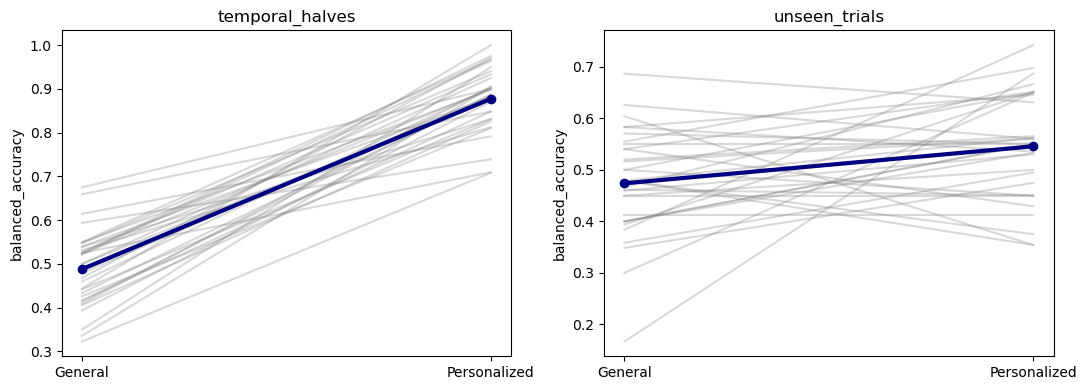

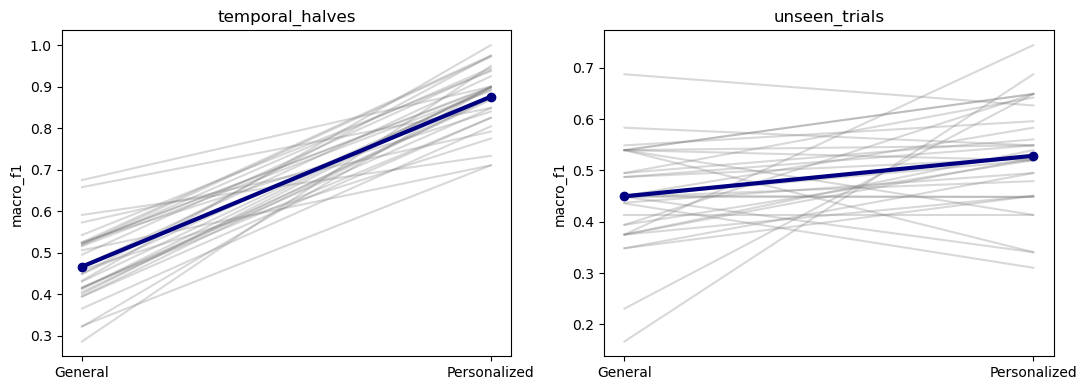

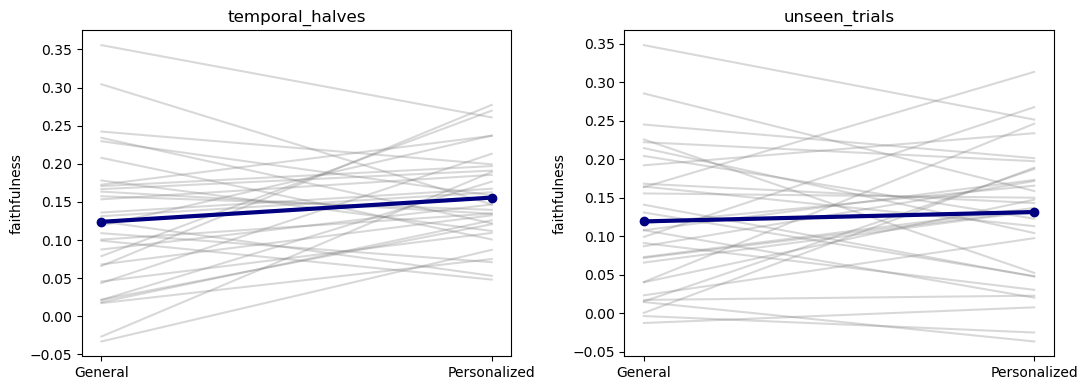

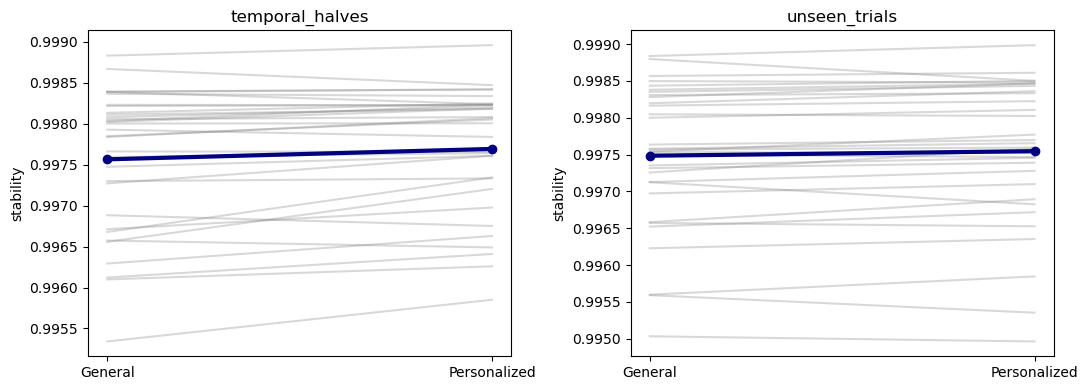

Saved results to D:\coding\python\HCI RESEARCH PROJECT\deap_professor_updated_results


In [9]:
def paired_summary(results):
    metrics=['balanced_accuracy','macro_f1','roc_auc']+(['faithfulness','stability'] if RUN_XAI else [])
    avg=results.groupby(['mode','protocol','subject','model'])[metrics].mean().reset_index()
    rows=[];rng=np.random.default_rng(2026)
    for (mode,protocol),part in avg.groupby(['mode','protocol']):
        for metric in metrics:
            wide=part.pivot(index='subject',columns='model',values=metric).dropna()
            d=(wide.personalized-wide.general).to_numpy()
            if not len(d): continue
            p=1.0 if np.allclose(d,0) else float(wilcoxon(d).pvalue)
            boot=rng.choice(d,size=(5000,len(d)),replace=True).mean(axis=1)
            rows.append({'mode':mode,'protocol':protocol,'metric':metric,'subjects':len(d),
                         'general_mean':wide.general.mean(),'personalized_mean':wide.personalized.mean(),
                         'mean_delta':d.mean(),'delta_ci_low':np.quantile(boot,.025),
                         'delta_ci_high':np.quantile(boot,.975),'wilcoxon_p':p})
    summary=pd.DataFrame(rows)
    order=np.argsort(summary.wilcoxon_p.to_numpy());p=summary.wilcoxon_p.to_numpy()[order]
    adjusted=np.minimum(1,np.maximum.accumulate(p*(len(p)-np.arange(len(p)))))
    summary['holm_p']=np.nan;summary.loc[summary.index[order],'holm_p']=adjusted
    return avg,summary

subject_averages,summary=paired_summary(results)
summary.to_csv(OUT/'paired_summary.csv',index=False)
display(summary)
for metric in ['balanced_accuracy','macro_f1']+(['faithfulness','stability'] if RUN_XAI else []):
    fig,axes=plt.subplots(1,len(PROTOCOLS),figsize=(11,4),squeeze=False)
    for ax,protocol in zip(axes[0],PROTOCOLS):
        part=subject_averages[(subject_averages['mode']=='baseline_relative')&(subject_averages.protocol==protocol)]
        w=part.pivot(index='subject',columns='model',values=metric)
        for _,r in w.iterrows():ax.plot([0,1],[r.general,r.personalized],alpha=.3,color='gray')
        ax.plot([0,1],[w.general.mean(),w.personalized.mean()],marker='o',color='navy',linewidth=3)
        ax.set(xticks=[0,1],xticklabels=['General','Personalized'],title=protocol,ylabel=metric)
    fig.tight_layout();fig.savefig(OUT/f'paired_{metric}.png',dpi=160);plt.show()
config={'feature_count':384,'sampling_rate':FS,'baseline_seconds':3,'half_seconds':HALF_SAMPLES/FS,
        'calibration_start_second':CALIBRATION_START_SECOND,'stimulus_skip_seconds':STIMULUS_SKIP_SAMPLES/FS,
        'stimulus_start_sample':STIMULUS_START_SAMPLE,'temporal_split_sample':TEMPORAL_SPLIT_SAMPLE,
        'correlation_threshold':CORRELATION_THRESHOLD,'calibration_weight':CALIBRATION_WEIGHT,
        'C':C,'seeds':SEEDS,'feature_modes':FEATURE_MODES,'protocols':PROTOCOLS,
        'run_xai':RUN_XAI,'xai_top_k':XAI_TOP_K,'xai_random_repeats':XAI_RANDOM_REPEATS,
        'xai_noise_repeats':XAI_NOISE_REPEATS,'xai_noise_sd':XAI_NOISE_SD,
        'class_weight':'balanced; recomputed on each fitting set',
        'metadata_reference_sha256':REFERENCE_SHA256,'label_source':'embedded participant_ratings.xls; Participant_id + Experiment_id',
        'versions':{'numpy':np.__version__,'scipy':scipy.__version__,'sklearn':sklearn.__version__}}
(OUT/'configuration.json').write_text(json.dumps(config,indent=2))
print('Saved results to',OUT.resolve())

## Interpretation and next steps
- Inspect stored-versus-metadata comparisons and confirm the corrected 572-low / 708-high class distribution before interpreting scores.
- Report baseline-relative versus stimulus-only results to separate resting-context effects from calibration effects.
- Temporal-half scores answer within-trial adaptation; unseen-trial scores answer transfer to separate trials. Neither is a live real-time deployment evaluation.
- Low pairwise correlations do not prove absence of multicollinearity; inspect VIF/rank/condition outputs.
- Faithfulness under masking is model-based evidence, not physiological causality or proof of usefulness to people. An HCI user evaluation would address perceived clarity/usefulness separately.
- Compare a tuned Elastic-Net Logistic Regression and constrained Random Forest later with identical splits and training-only tuning; no accuracy gain is guaranteed. Do not change the model family and calibration protocol simultaneously when attributing an effect to personalization.
- For publication-quality confirmation, repeat calibration splits, predefine the primary contrast and noninferiority margin, examine grouped-feature perturbations, and use realistic perturbations for correlated EEG features.

References: [Official DEAP access](https://www.eecs.qmul.ac.uk/mmv/datasets/deap/), [scikit-learn correlated importance example](https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance_multicollinear.html), [Linear models](https://scikit-learn.org/stable/modules/linear_model.html).

**Validation status:** syntax and synthetic pipeline checks are performed by the notebook author; actual DEAP extraction, label verification and scientific results require running locally with the dataset. Pickle and joblib should only load trusted files.